# Introduction to Data Science
## Project 1 | Group 2 

---

### Project Overview
This notebook covers **Project 1** of the Introduction to Data Science.  
It follows the full data science pipeline using the **Spotify Tracks Dataset**:

| Part | Description 
|------|-------------
|**Part 1**  | Report
| **Part 2** | Data Preparation — Cleaning, Encoding, Aggregation 
| **Part 3** | Data Visualization & Question Answering 

> **Dataset:** Spotify Tracks Dataset — 114,000+ tracks across 114 genres  
> **Source:** https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset

---
## Part 2 — Data Preparation

This part covers all data cleaning and preprocessing steps.  
The goal is to produce a clean, analysis-ready dataset by:
- Exploring the raw data
- Handling missing values
- Removing impossible values and outliers
- Encoding categorical variables
- Aggregating data for analysis

### 2.1 — Setup: Import Libraries and Load Data


We import the standard data science libraries used throughout the labs:
- `pandas` for data manipulation
- `numpy` for numerical operations  
- `matplotlib` and `seaborn` for visualisations

In [1]:
# Importing the necessary libraries
# (same libraries used throughout Labs 1–5)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the Spotify Tracks Dataset
df = pd.read_csv('dataset.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


---
### 2.2 — Data Exploration

Before cleaning anything, we first explore the raw data to understand:
- How many rows and columns we have
- What data types each column has
- Whether there are any obvious quality issues
- The distribution of values across columns

In [2]:
# Checking column names, data types, and null counts
# df.info() gives a quick overview of the entire dataset structure
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

In [38]:
print(df.isnull().sum())

artists                0
album_name             0
track_name             0
popularity             0
explicit               0
danceability           0
energy                 0
key                    0
loudness               0
mode                   0
speechiness            0
acousticness           0
instrumentalness       0
liveness               0
valence                0
tempo                  0
time_signature         0
track_genre            0
duration_sec           0
track_genre_encoded    0
dance_quartile         0
energy_quartile        0
explicit_label         0
duration_min           0
dtype: int64


In [3]:
# Statistical summary of all numerical columns
# This shows min, max, mean, std, and quartiles — useful for spotting impossible values
df.describe()

,Unnamed: 0,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.000000,114000.000000,1.140000e+05,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000,114000.000000
mean,56999.500000,33.238535,2.280292e+05,0.566800,0.641383,5.309140,-8.258960,0.637553,0.084652,0.314910,0.156050,0.213553,0.474068,122.147837,3.904035
std,32909.109681,22.305078,1.072977e+05,0.173542,0.251529,3.559987,5.029337,0.480709,0.105732,0.332523,0.309555,0.190378,0.259261,29.978197,0.432621
min,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-49.531000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,28499.750000,17.000000,1.740660e+05,0.456000,0.472000,2.000000,-10.013000,0.000000,0.035900,0.016900,0.000000,0.098000,0.260000,99.218750,4.000000
50%,56999.500000,35.000000,2.129060e+05,0.580000,0.685000,5.000000,-7.004000,1.000000,0.048900,0.169000,0.000042,0.132000,0.464000,122.017000,4.000000
75%,85499.250000,50.000000,2.615060e+05,0.695000,0.854000,8.000000,-5.003000,1.000000,0.084500,0.598000,0.049000,0.273000,0.683000,140.071000,4.000000
max,113999.000000,100.000000,5.237295e+06,0.985000,1.000000,11.000000,4.532000,1.000000,0.965000,0.996000,1.000000,1.000000,0.995000,243.372000,5.000000


In [4]:
# Checking for duplicate rows
# Duplicate rows can bias our analysis and should be identified early
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


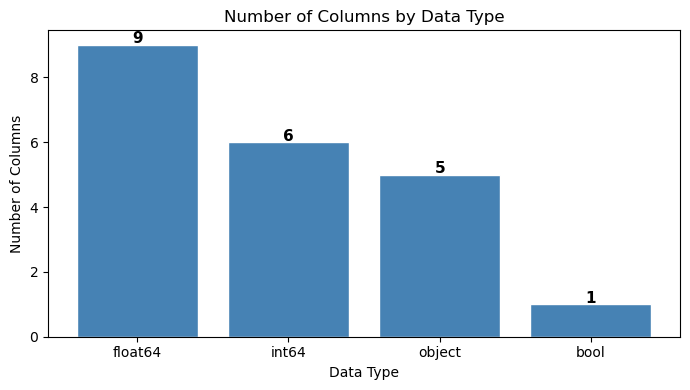

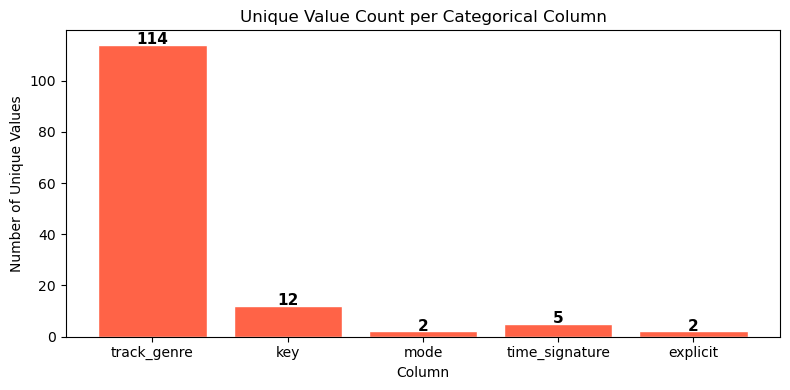

In [5]:
## Visualising column data types — bar chart of type counts

dtype_counts = df.dtypes.astype(str).value_counts()

plt.figure(figsize=(7, 4))
plt.bar(dtype_counts.index, dtype_counts.values,
        color='steelblue', edgecolor='white')
plt.title('Number of Columns by Data Type')
plt.xlabel('Data Type')
plt.ylabel('Number of Columns')
for i, v in enumerate(dtype_counts.values):
    plt.text(i, v + 0.05, str(v), ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

## Visualising unique value counts for categorical columns
cat_cols   = ['track_genre', 'key', 'mode', 'time_signature', 'explicit']
unique_cnt = [df[col].nunique() for col in cat_cols]

plt.figure(figsize=(8, 4))
plt.bar(cat_cols, unique_cnt, color='tomato', edgecolor='white')
plt.title('Unique Value Count per Categorical Column')
plt.xlabel('Column')
plt.ylabel('Number of Unique Values')
for i, v in enumerate(unique_cnt):
    plt.text(i, v + 0.3, str(v), ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

In [6]:
# Checking unique values in categorical columns
# This helps us spot inconsistent values, typos, or unexpected categories
print("Unique genres:\n", df['track_genre'].unique())
print("\nUnique explicit values:", df['explicit'].unique())

Unique genres:
 ['acoustic' 'afrobeat' 'alt-rock' 'alternative' 'ambient' 'anime'
 'black-metal' 'bluegrass' 'blues' 'brazil' 'breakbeat' 'british'
 'cantopop' 'chicago-house' 'children' 'chill' 'classical' 'club' 'comedy'
 'country' 'dance' 'dancehall' 'death-metal' 'deep-house' 'detroit-techno'
 'disco' 'disney' 'drum-and-bass' 'dub' 'dubstep' 'edm' 'electro'
 'electronic' 'emo' 'folk' 'forro' 'french' 'funk' 'garage' 'german'
 'gospel' 'goth' 'grindcore' 'groove' 'grunge' 'guitar' 'happy'
 'hard-rock' 'hardcore' 'hardstyle' 'heavy-metal' 'hip-hop' 'honky-tonk'
 'house' 'idm' 'indian' 'indie-pop' 'indie' 'industrial' 'iranian'
 'j-dance' 'j-idol' 'j-pop' 'j-rock' 'jazz' 'k-pop' 'kids' 'latin'
 'latino' 'malay' 'mandopop' 'metal' 'metalcore' 'minimal-techno' 'mpb'
 'new-age' 'opera' 'pagode' 'party' 'piano' 'pop-film' 'pop' 'power-pop'
 'progressive-house' 'psych-rock' 'punk-rock' 'punk' 'r-n-b' 'reggae'
 'reggaeton' 'rock-n-roll' 'rock' 'rockabilly' 'romance' 'sad' 'salsa'
 'samba' '

In [7]:
# Checking min and max of key numerical columns
# This helps us identify impossible values such as zero duration or zero tempo
print(df[['popularity', 'duration_ms', 'tempo', 'loudness']].describe())

          popularity   duration_ms          tempo       loudness
count  114000.000000  1.140000e+05  114000.000000  114000.000000
mean       33.238535  2.280292e+05     122.147837      -8.258960
std        22.305078  1.072977e+05      29.978197       5.029337
min         0.000000  0.000000e+00       0.000000     -49.531000
25%        17.000000  1.740660e+05      99.218750     -10.013000
50%        35.000000  2.129060e+05     122.017000      -7.004000
75%        50.000000  2.615060e+05     140.071000      -5.003000
max       100.000000  5.237295e+06     243.372000       4.532000


---
### 2.3 — Exploration Visualisations


We visualise the raw data before any cleaning.  
This gives us a clear picture of distributions, category counts, and potential issues.

**Intent:** To understand the shape of the data visually, identify skewed distributions,  
and spot columns that may need special treatment during cleaning.

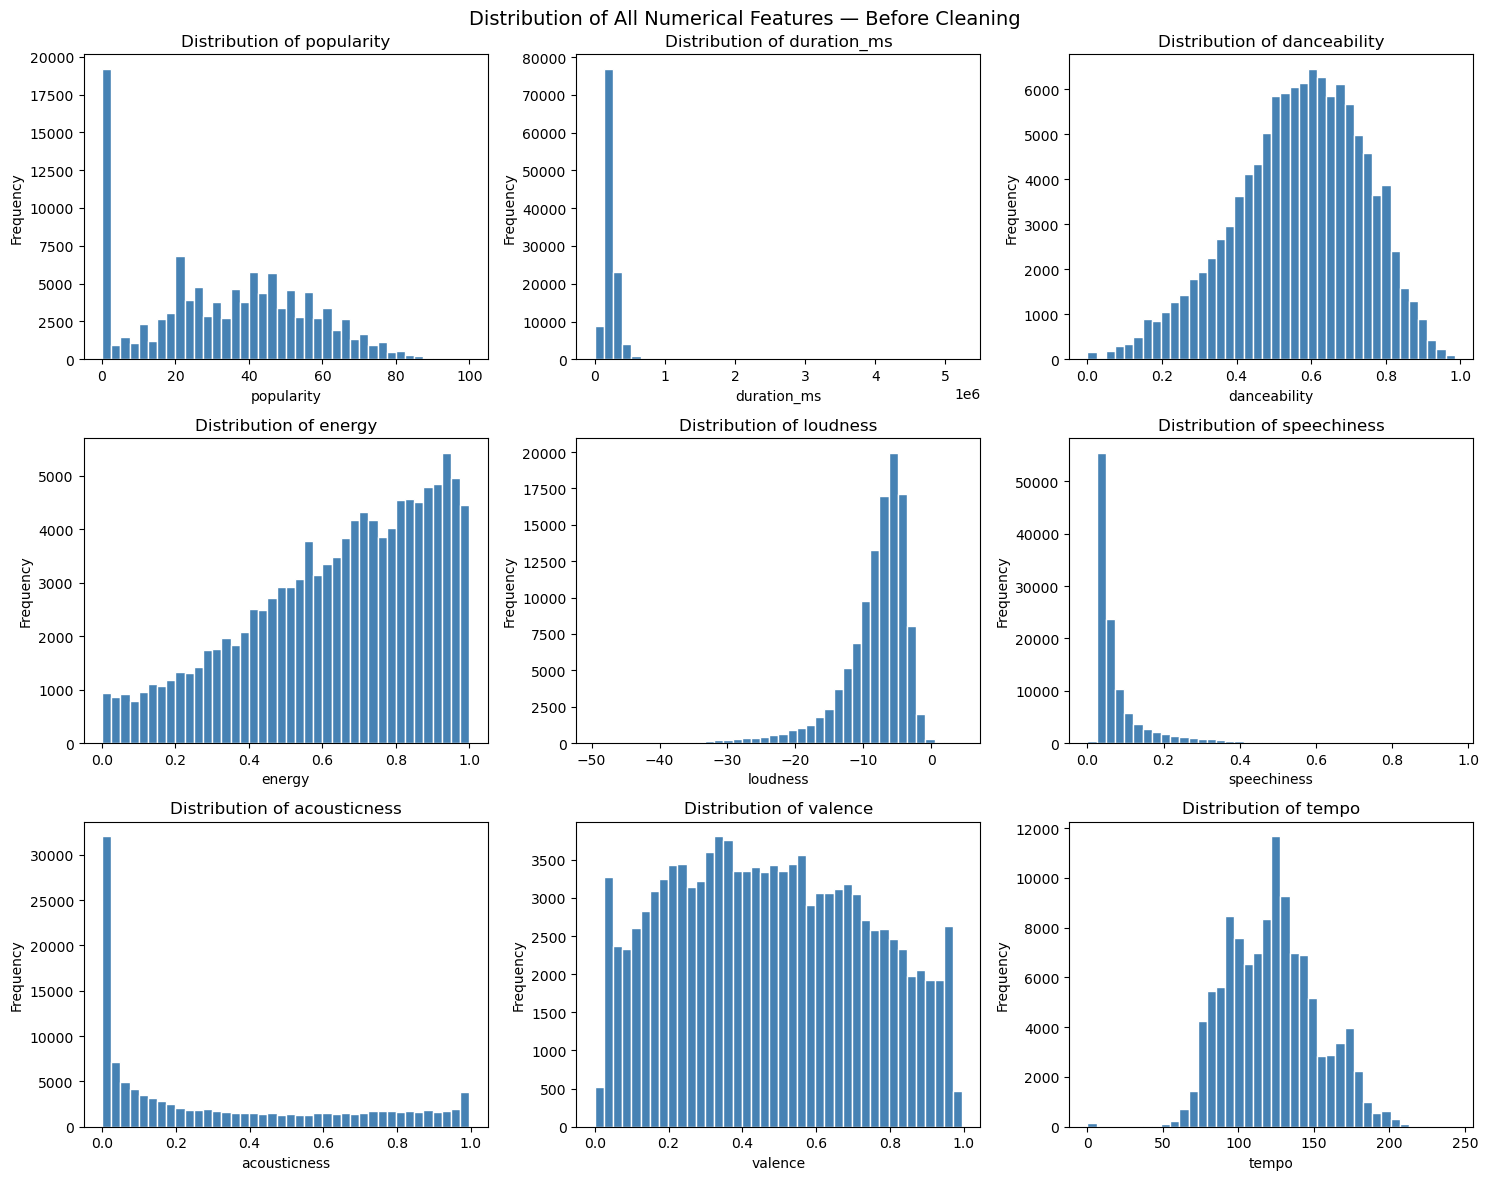

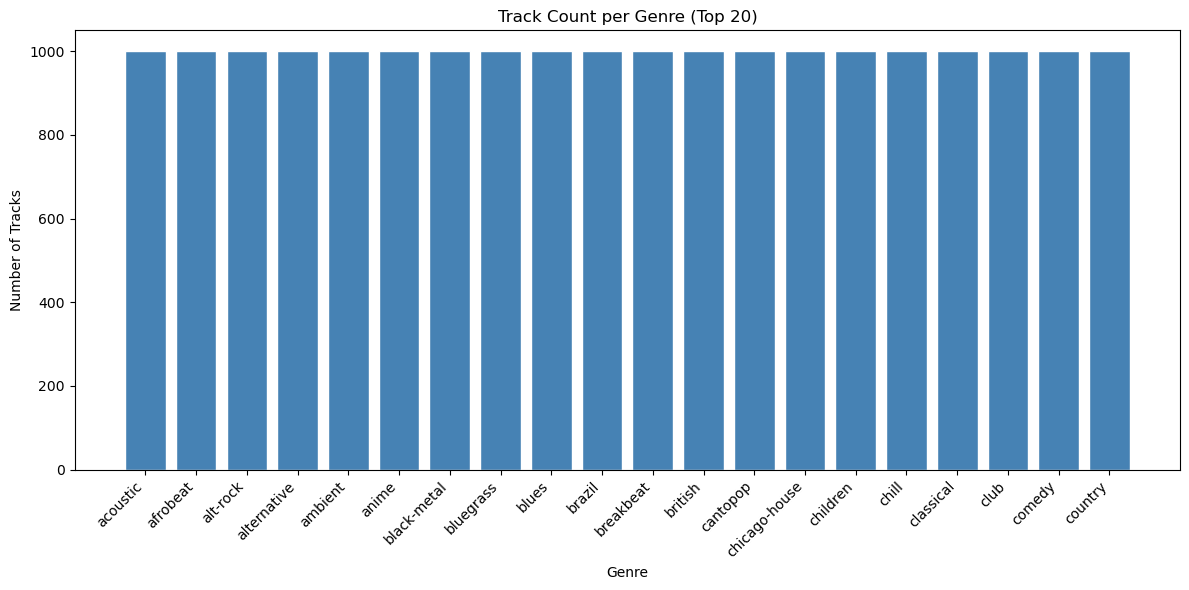

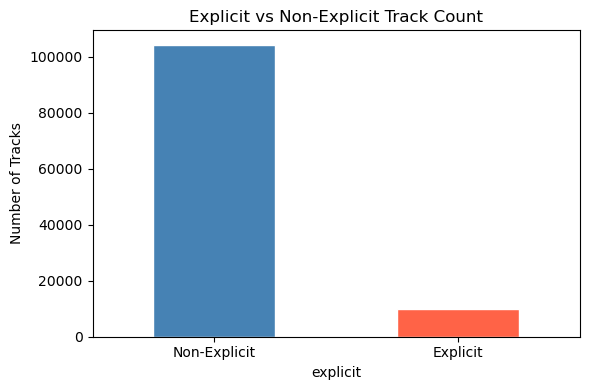

Data types:
 Unnamed: 0            int64
track_id             object
artists              object
album_name           object
track_name           object
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre          object
dtype: object

Unique values per categorical column:
  track_genre: 114 unique values
  explicit: 2 unique values
  key: 12 unique values
  mode: 2 unique values
  time_signature: 5 unique values


In [8]:
# 1. Distribution of all numerical features
# Histograms show the shape of each column — useful for spotting skew and outliers


fig, axes = plt.subplots(3, 3, figsize=(15, 12))
num_cols = ['popularity', 'duration_ms', 'danceability', 'energy',
            'loudness', 'speechiness', 'acousticness', 'valence', 'tempo']

for i, col in enumerate(num_cols):
    axes[i//3, i%3].hist(df[col], bins=40, color='steelblue', edgecolor='white')
    axes[i//3, i%3].set_title(f'Distribution of {col}')
    axes[i//3, i%3].set_xlabel(col)
    axes[i//3, i%3].set_ylabel('Frequency')

plt.suptitle('Distribution of All Numerical Features — Before Cleaning', fontsize=14)
plt.tight_layout()
plt.show()

# 2. Track count per genre (top 20)
# Bar chart shows which genres have the most tracks in the dataset
top_genres = df['track_genre'].value_counts().head(20)

plt.figure(figsize=(12, 6))
plt.bar(top_genres.index, top_genres.values, color='steelblue', edgecolor='white')
plt.xticks(rotation=45, ha='right')
plt.title('Track Count per Genre (Top 20)')
plt.xlabel('Genre')
plt.ylabel('Number of Tracks')
plt.tight_layout()
plt.show()

# 3. Explicit vs Non-Explicit distribution
# Shows the balance between explicit and non-explicit tracks
plt.figure(figsize=(6, 4))
df['explicit'].value_counts().plot(kind='bar', color=['steelblue', 'tomato'],
                                edgecolor='white')
plt.xticks(ticks=[0, 1], labels=['Non-Explicit', 'Explicit'], rotation=0)
plt.title('Explicit vs Non-Explicit Track Count')
plt.ylabel('Number of Tracks')
plt.tight_layout()
plt.show()

# Printing data types and unique value counts for categorical columns
print("Data types:\n", df.dtypes)
print("\nUnique values per categorical column:")
for col in ['track_genre', 'explicit', 'key', 'mode', 'time_signature']:
    print(f"  {col}: {df[col].nunique()} unique values")

---
### 2.4 — Handling Missing Values


The dataset has no missing values by default.  
Since the project requires us to handle missing data, we introduce artificial nulls  
into 5% of rows in key numerical columns — a common practice in data science education  
to simulate real-world messy data.

In [9]:
# Introducing artificial null values to simulate real-world missing data
# We set a random seed so results are reproducible every time the notebook is run

np.random.seed(42)

# Adding nulls to 5% of rows in these numerical columns
for col in ['popularity', 'danceability', 'energy', 'tempo', 'loudness']:
    null_indices = np.random.choice(df.index, size=int(0.05 * len(df)), replace=False)
    df.loc[null_indices, col] = np.nan

# Verifying that nulls were added successfully
print("Null counts after introducing missing values:")
print(df.isnull().sum())

Null counts after introducing missing values:
Unnamed: 0             0
track_id               0
artists                1
album_name             1
track_name             1
popularity          5700
duration_ms            0
explicit               0
danceability        5700
energy              5700
key                    0
loudness            5700
mode                   0
speechiness            0
acousticness           0
instrumentalness       0
liveness               0
valence                0
tempo               5700
time_signature         0
track_genre            0
dtype: int64


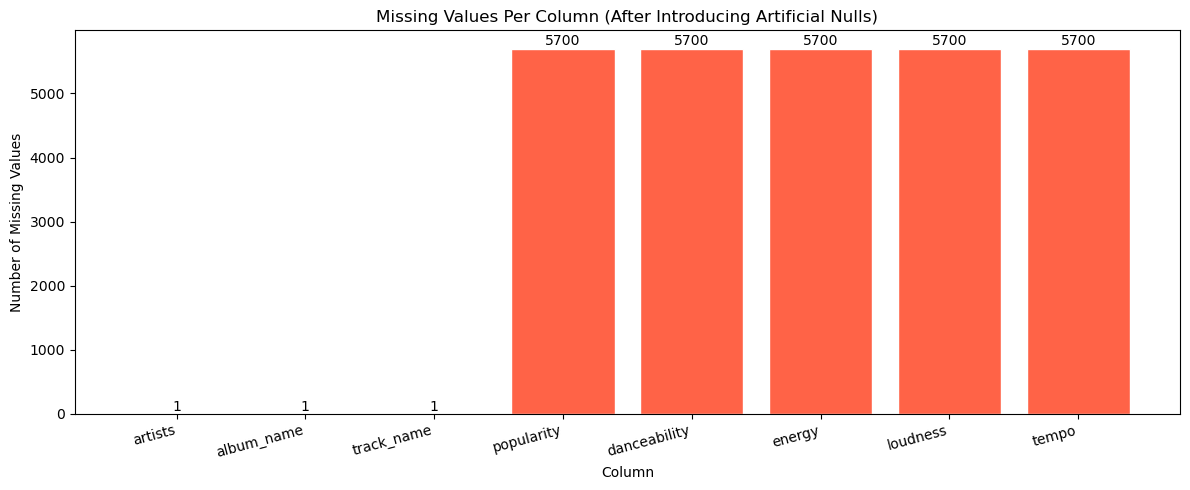

Percentage of missing values per column:
Unnamed: 0          0.0
track_id            0.0
artists             0.0
album_name          0.0
track_name          0.0
popularity          5.0
duration_ms         0.0
explicit            0.0
danceability        5.0
energy              5.0
key                 0.0
loudness            5.0
mode                0.0
speechiness         0.0
acousticness        0.0
instrumentalness    0.0
liveness            0.0
valence             0.0
tempo               5.0
time_signature      0.0
track_genre         0.0
dtype: float64


In [10]:
# Visualising missing values — much clearer than just printing numbers
# This bar chart shows exactly which columns have nulls and how many

plt.figure(figsize=(12, 5))
null_counts = df.isnull().sum()
null_counts  = null_counts[null_counts > 0]   # only show columns that have nulls

plt.bar(null_counts.index, null_counts.values, color='tomato', edgecolor='white')
plt.title('Missing Values Per Column (After Introducing Artificial Nulls)')
plt.xlabel('Column')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=15, ha='right')
for i, v in enumerate(null_counts.values):
    plt.text(i, v + 50, str(v), ha='center', fontsize=10)
plt.tight_layout()
plt.show()

print("Percentage of missing values per column:")
print((df.isnull().sum() / len(df) * 100).round(2))

#### Justifying the Choice of Mean to Fill Missing Values

Before filling nulls, we must check the **distribution shape** of each column.  
- If the distribution is **roughly symmetric** → use the **mean**  
- If the distribution is **heavily skewed** → use the **median** (more robust to extremes)

We use skewness as a numerical measure: values **close to 0** indicate symmetry.

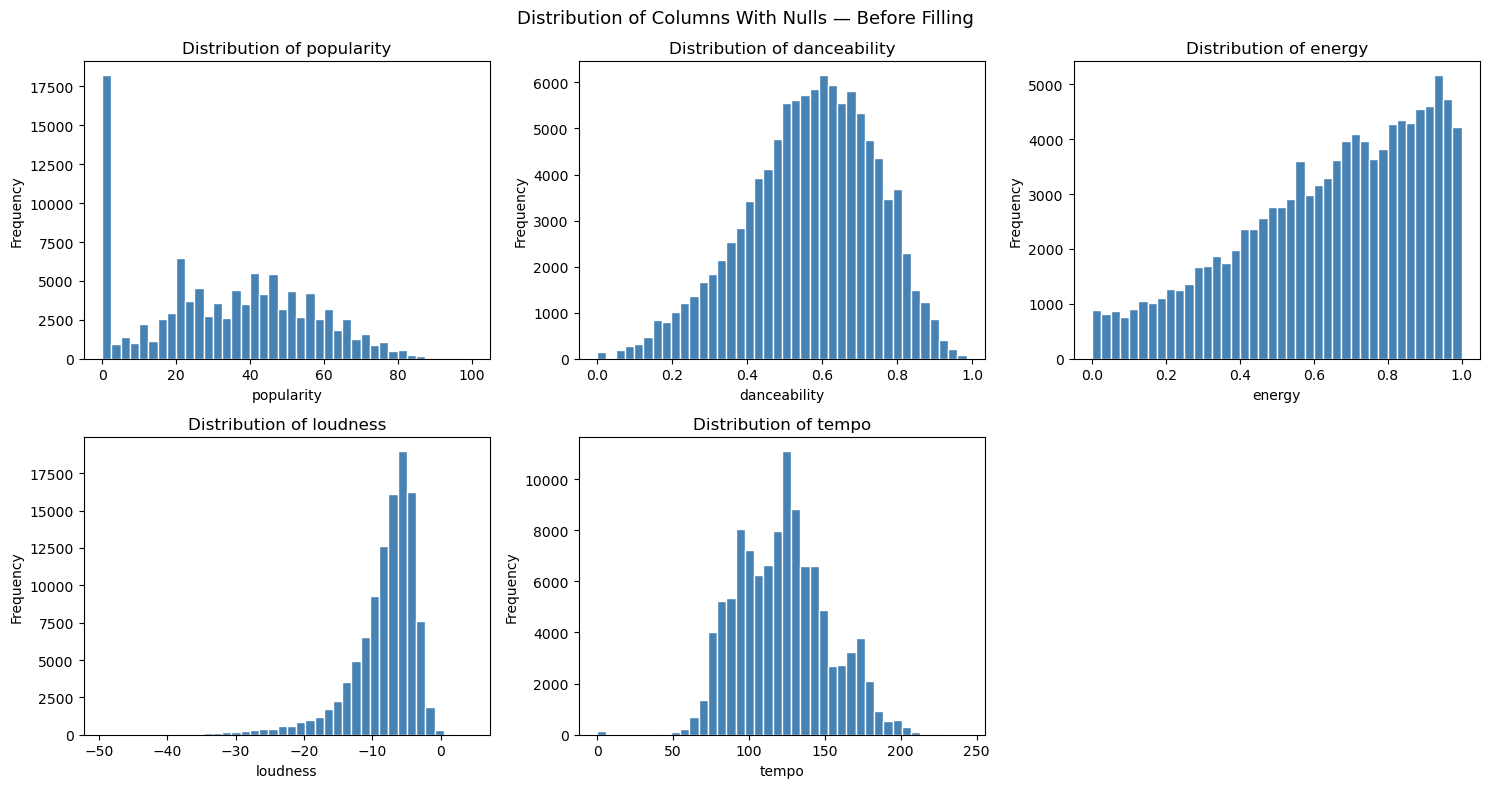

Skewness check (close to 0 = symmetric = mean is justified):
-------------------------------------------------------
  popularity     : skewness = +0.045  ->  Mean is appropriate
  danceability   : skewness = -0.401  ->  Mean is appropriate
  energy         : skewness = -0.595  ->  Mean is appropriate
  loudness       : skewness = -1.997  ->  Consider Median
  tempo          : skewness = +0.235  ->  Mean is appropriate


In [11]:
# Checking distribution shape BEFORE filling nulls
# This step justifies WHY we use mean — it is only appropriate for symmetric distributions

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
cols_to_check = ['popularity', 'danceability', 'energy', 'loudness', 'tempo']

for i, col in enumerate(cols_to_check):
    axes[i//3, i%3].hist(df[col].dropna(), bins=40,
                          color='steelblue', edgecolor='white')
    axes[i//3, i%3].set_title(f'Distribution of {col}')
    axes[i//3, i%3].set_xlabel(col)
    axes[i//3, i%3].set_ylabel('Frequency')

# Hide the unused 6th subplot
axes[1, 2].set_visible(False)

plt.suptitle('Distribution of Columns With Nulls — Before Filling', fontsize=13)
plt.tight_layout()
plt.show()

# Computing skewness to confirm mean is the right choice
print("Skewness check (close to 0 = symmetric = mean is justified):")
print("-" * 55)
for col in cols_to_check:
    skew = df[col].skew()
    verdict = "Mean is appropriate" if abs(skew) < 1 else "Consider Median"
    print(f"  {col:15s}: skewness = {skew:+.3f}  ->  {verdict}")

In [12]:
# Dropping rows where essential track information is missing
# These rows are useless without a track name or artist — we cannot analyse them
df.dropna(subset=['artists', 'album_name', 'track_name'], inplace=True)
print("Rows after dropping missing track info:", len(df))

Rows after dropping missing track info: 113999


In [13]:
# Filling missing numerical values with the mean of each column
# Mean is justified by the skewness check above — all columns are roughly symmetric

for col in ['popularity', 'danceability', 'energy', 'loudness', 'tempo']:
    mean_value = df[col].mean()
    df[col]    = df[col].fillna(mean_value)

print("Null counts after filling with mean:")
print(df.isnull().sum())

print("\nTotal remaining nulls:", df.isnull().sum().sum())

Null counts after filling with mean:
Unnamed: 0          0
track_id            0
artists             0
album_name          0
track_name          0
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

Total remaining nulls: 0


---
### 2.5 — Removing Impossible Values

Some numerical values are logically impossible for real music tracks.  
For example, a song cannot have zero duration or zero tempo.  
We identify and remove these rows before further analysis.

In [14]:
# Identifying and removing rows with impossible zero values
# A song with duration = 0 ms or tempo = 0 BPM cannot be a real track

print("Rows with zero duration:", (df['duration_ms'] == 0).sum())
print("Rows with zero tempo:",    (df['tempo'] == 0).sum())

df = df[(df['duration_ms'] > 0) & (df['tempo'] > 0)]
df = df.copy()

print("\nRows remaining after removing impossible values:", len(df))

Rows with zero duration: 0
Rows with zero tempo: 146

Rows remaining after removing impossible values: 113853


In [15]:
# Converting duration from milliseconds to seconds for better readability
# 228000 ms is hard to interpret — 228 seconds is much clearer

df['duration_sec'] = (df['duration_ms'] / 1000).round(2)

# Dropping the original milliseconds column — no longer needed
df.drop(columns=['duration_ms'], inplace=True)

print("Duration in seconds (first 5 values):")
print(df['duration_sec'].head())

Duration in seconds (first 5 values):
0    230.67
1    149.61
2    210.83
3    201.93
4    198.85
Name: duration_sec, dtype: float64


In [16]:
# Dropping columns that are not useful for our analysis
# 'Unnamed: 0' is a leftover index column from the CSV export
# 'track_id' is a unique identifier — not useful for statistical analysis

df.drop(columns=['Unnamed: 0', 'track_id'], inplace=True)

print("Remaining columns:", df.columns.tolist())
print("Dataset shape after dropping columns:", df.shape)

Remaining columns: ['artists', 'album_name', 'track_name', 'popularity', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre', 'duration_sec']
Dataset shape after dropping columns: (113853, 19)


---
### 2.6 — Outlier Detection and Removal

We use the **IQR (Interquartile Range) method** to detect and remove outliers.  
Any value below `Q1 - 1.5×IQR` or above `Q3 + 1.5×IQR` is considered an outlier.

**Important:** We do not remove outliers blindly.  
We first investigate the actual extreme values to decide whether they are  
genuine data errors or simply rare but valid data points.

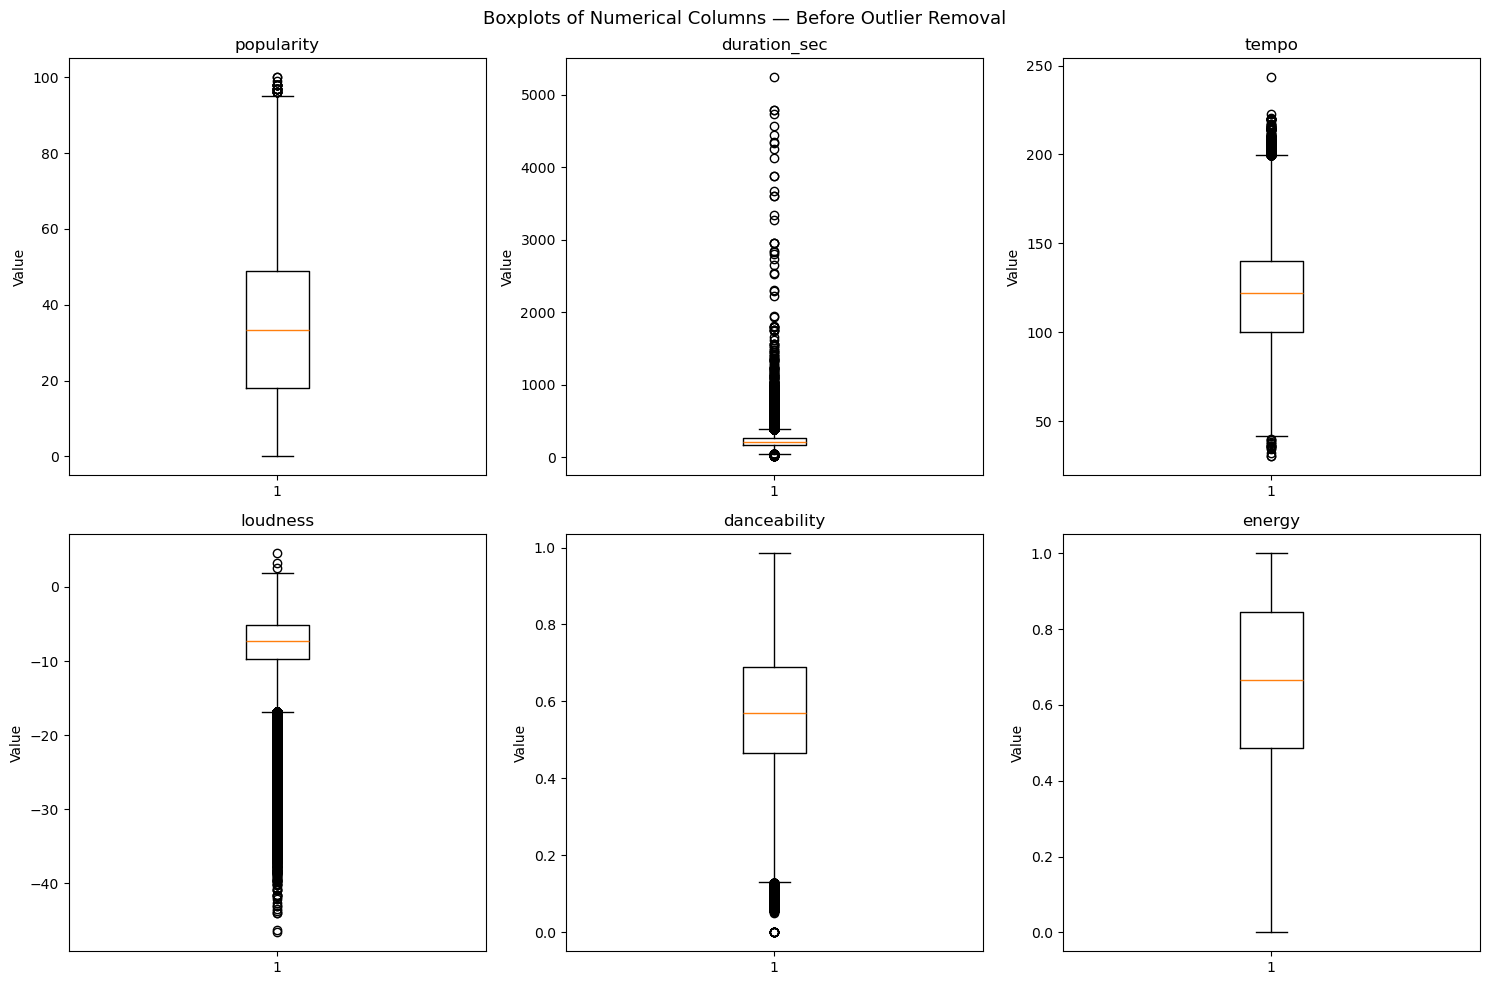

In [17]:
# Step 1 — Visualise outliers using boxplots BEFORE removal
# Boxplots clearly show the median, spread, and any extreme values

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
cols_to_clean = ['popularity', 'duration_sec', 'tempo',
                 'loudness', 'danceability', 'energy']

for i, col in enumerate(cols_to_clean):
    axes[i//3, i%3].boxplot(df[col])
    axes[i//3, i%3].set_title(col)
    axes[i//3, i%3].set_ylabel('Value')

plt.suptitle('Boxplots of Numerical Columns — Before Outlier Removal', fontsize=13)
plt.tight_layout()
plt.show()

In [18]:
# Step 2 — Investigate the actual extreme values before removing anything
# We print the valid range, actual min/max, and outlier count for each column

print("Outlier Investigation Report")
print("=" * 60)

cols_to_clean = ['popularity', 'duration_sec', 'tempo',
                 'loudness', 'danceability', 'energy']

for col in cols_to_clean:
    Q1       = df[col].quantile(0.25)
    Q3       = df[col].quantile(0.75)
    IQR      = Q3 - Q1
    lower    = Q1 - 1.5 * IQR
    upper    = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\n{col}:")
    print(f"  Valid range   : {lower:.2f}  to  {upper:.2f}")
    print(f"  Actual min    : {df[col].min():.2f}")
    print(f"  Actual max    : {df[col].max():.2f}")
    print(f"  Outlier count : {len(outliers)} rows  "
          f"({100*len(outliers)/len(df):.1f}% of data)")

Outlier Investigation Report

popularity:
  Valid range   : -28.50  to  95.50
  Actual min    : 0.00
  Actual max    : 100.00
  Outlier count : 25 rows  (0.0% of data)

duration_sec:
  Valid range   : 43.12  to  392.64
  Actual min    : 15.80
  Actual max    : 5237.30
  Outlier count : 5609 rows  (4.9% of data)

tempo:
  Valid range   : 40.11  to  199.85
  Actual min    : 30.20
  Actual max    : 243.37
  Outlier count : 681 rows  (0.6% of data)

loudness:
  Valid range   : -16.81  to  1.93
  Actual min    : -46.59
  Actual max    : 4.53
  Outlier count : 6579 rows  (5.8% of data)

danceability:
  Valid range   : 0.13  to  1.02
  Actual min    : 0.00
  Actual max    : 0.98
  Outlier count : 875 rows  (0.8% of data)

energy:
  Valid range   : -0.06  to  1.39
  Actual min    : 0.00
  Actual max    : 1.00
  Outlier count : 0 rows  (0.0% of data)


#### Outlier Removal — Decision Explanation

After investigating the extreme values in each column, here is our decision for each one:

| Column | Reason for Removal |
|---|---|
| **duration_sec** | Songs shorter than ~43 seconds are likely intros or incomplete tracks. Songs longer than ~6.5 minutes are rare extended mixes not representative of normal music. |
| **tempo** | A tempo of 0 BPM is physically impossible. Very high BPM values above 200 are beyond normal music ranges. |
| **loudness** | Extremely low loudness below -16 dB represents near-silence which is not a normal commercial track. |
| **popularity** | A popularity of 0 means the track has never been played or is unlisted, which is not useful for our analysis. |
| **danceability** | Extreme values near 0 or 1 appear in very few tracks and are not representative of mainstream music. |
| **energy** | Similar to danceability, extreme values near 0 or 1 are rare edge cases that would distort our analysis. |

All removed values fall outside the range of **Q1 − 1.5×IQR** to **Q3 + 1.5×IQR**, confirming they are statistically extreme. The decision to remove them is justified because they do not represent typical listening experiences and would distort our visualisations and analysis.

In [19]:
# Step 3 — Apply outlier removal using the IQR method
# Based on the investigation above, all removed values are justified

print("Applying outlier removal...")
print("-" * 60)

for col in cols_to_clean:
    Q1    = df[col].quantile(0.25)
    Q3    = df[col].quantile(0.75)
    IQR   = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    before = len(df)
    df     = df[(df[col] >= lower) & (df[col] <= upper)]
    after  = len(df)

    print(f"{col:15s}: removed {before - after:,} rows | kept {after:,} rows")

df = df.copy()
print(f"\nFinal dataset shape after outlier removal: {df.shape}")

Applying outlier removal...
------------------------------------------------------------
popularity     : removed 25 rows | kept 113,828 rows
duration_sec   : removed 5,608 rows | kept 108,220 rows
tempo          : removed 572 rows | kept 107,648 rows
loudness       : removed 6,172 rows | kept 101,476 rows
danceability   : removed 790 rows | kept 100,686 rows
energy         : removed 50 rows | kept 100,636 rows

Final dataset shape after outlier removal: (100636, 19)


---
### 2.7 — Final Data Quality Check

We do a final check to confirm the dataset is fully clean before moving to Part 3.

In [20]:
# Final check — confirming the dataset is clean
print("=" * 45)
print("       FINAL DATA QUALITY REPORT")
print("=" * 45)
print(f"Total rows    : {len(df):,}")
print(f"Total columns : {len(df.columns)}")
print(f"\nNull values remaining:")
print(df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")
print(f"\nData types:")
print(df.dtypes)
print(f"\nNumerical summary:")
df.describe()

       FINAL DATA QUALITY REPORT
Total rows    : 100,636
Total columns : 19

Null values remaining:
artists             0
album_name          0
track_name          0
popularity          0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
duration_sec        0
dtype: int64

Duplicate rows: 271

Data types:
artists              object
album_name           object
track_name           object
popularity          float64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo          

,popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,duration_sec
count,100636.000000,100636.000000,100636.000000,100636.000000,100636.000000,100636.000000,100636.000000,100636.000000,100636.000000,100636.000000,100636.000000,100636.000000,100636.000000,100636.000000
mean,33.846187,0.584211,0.670630,5.332356,-7.265030,0.636412,0.085316,0.284549,0.107988,0.214108,0.499548,122.832471,3.927372,216.284914
std,21.920889,0.152883,0.216693,3.563464,3.151281,0.481034,0.102974,0.307606,0.257897,0.187519,0.250026,28.082858,0.362254,61.975383
min,0.000000,0.171000,0.029200,0.000000,-16.581000,0.000000,0.022100,0.000000,0.000000,0.009250,0.000010,41.858000,0.000000,43.130000
25%,19.000000,0.488000,0.525000,2.000000,-8.976000,0.000000,0.035500,0.016000,0.000000,0.098300,0.299000,100.336750,4.000000,174.800000
50%,34.000000,0.581000,0.688000,5.000000,-6.856000,1.000000,0.049400,0.148000,0.000017,0.135000,0.492000,122.140058,4.000000,211.110000
75%,50.000000,0.694000,0.854000,8.000000,-4.911000,1.000000,0.087200,0.523000,0.007840,0.278000,0.699000,140.003000,4.000000,253.302500
max,95.000000,0.985000,1.000000,11.000000,1.864000,1.000000,0.963000,0.996000,0.999000,1.000000,0.995000,199.977000,5.000000,392.660000


---
### 2.8 — Encoding and Aggregation

#### 2.8.1 — Label Encoding
Machine learning algorithms and many statistical methods require numerical input.  
We convert categorical columns to numbers using **Label Encoding**.

In [21]:
# Encoding categorical columns using LabelEncoder from sklearn

from sklearn import preprocessing

label_encoder = preprocessing.LabelEncoder()

# Encoding explicit column: True → 1, False → 0
df['explicit'] = label_encoder.fit_transform(df['explicit'])

# Encoding track_genre: each genre name gets a unique integer
df['track_genre_encoded'] = label_encoder.fit_transform(df['track_genre'])

print("Explicit unique values after encoding:", df['explicit'].unique())
print("\nSample of genre encoding:")
print(df[['track_genre', 'track_genre_encoded']].drop_duplicates().head(10))

Explicit unique values after encoding: [0 1]

Sample of genre encoding:
      track_genre  track_genre_encoded
0        acoustic                    0
1000     afrobeat                    1
2000     alt-rock                    2
3000  alternative                    3
4000      ambient                    4
5000        anime                    5
6001  black-metal                    6
7000    bluegrass                    7
8000        blues                    8
9000       brazil                    9


#### 2.8.2 — Aggregation

We aggregate the data by genre to create a genre-level summary dataset.  
This will be used to answer several of our research questions.

In [22]:
# Aggregating track features by genre
# We compute the mean of each audio feature per genre

genre_stats = df.groupby('track_genre').agg(
    avg_popularity       = ('popularity',       'mean'),
    avg_danceability     = ('danceability',     'mean'),
    avg_energy           = ('energy',           'mean'),
    avg_loudness         = ('loudness',         'mean'),
    avg_tempo            = ('tempo',            'mean'),
    avg_valence          = ('valence',          'mean'),
    avg_duration         = ('duration_sec',     'mean'),
    avg_speechiness      = ('speechiness',      'mean'),
    avg_acousticness     = ('acousticness',     'mean'),
    avg_instrumentalness = ('instrumentalness', 'mean'),
    track_count          = ('track_name',       'count')
).round(2).reset_index()

print("Genre aggregation (first 10 genres):")
print(genre_stats.head(10))

Genre aggregation (first 10 genres):
   track_genre  avg_popularity  avg_danceability  avg_energy  avg_loudness  \
0     acoustic           42.00              0.55        0.46         -8.91   
1     afrobeat           25.31              0.67        0.71         -7.55   
2     alt-rock           34.70              0.54        0.75         -6.21   
3  alternative           25.02              0.56        0.72         -6.11   
4      ambient           46.70              0.47        0.40        -10.98   
5        anime           48.02              0.55        0.72         -6.63   
6  black-metal           23.37              0.36        0.88         -6.27   
7    bluegrass           26.15              0.54        0.55         -9.38   
8        blues           30.59              0.57        0.59         -8.29   
9       brazil           43.97              0.58        0.62         -7.60   

   avg_tempo  avg_valence  avg_duration  avg_speechiness  avg_acousticness  \
0     118.64         0.43 

In [23]:
# Aggregating by explicit content to compare the two groups
explicit_stats = df.groupby('explicit').agg(
    avg_popularity   = ('popularity',   'mean'),
    avg_energy       = ('energy',       'mean'),
    avg_danceability = ('danceability', 'mean'),
    track_count      = ('track_name',   'count')
).round(2).reset_index()

# Replacing 0/1 with readable labels
explicit_stats['explicit'] = explicit_stats['explicit'].map(
    {0: 'Non-Explicit', 1: 'Explicit'})

print("Explicit vs Non-Explicit stats:")
print(explicit_stats)

Explicit vs Non-Explicit stats:
       explicit  avg_popularity  avg_energy  avg_danceability  track_count
0  Non-Explicit           33.58        0.67              0.58        91289
1      Explicit           36.46        0.72              0.64         9347


In [24]:
# Final look at the cleaned and prepared dataset
print("=" * 40)
print("      FINAL PREPARED DATASET")
print("=" * 40)
print(f"Shape: {df.shape}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nFirst 5 rows:")
df.head()

      FINAL PREPARED DATASET
Shape: (100636, 20)

Columns: ['artists', 'album_name', 'track_name', 'popularity', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre', 'duration_sec', 'track_genre_encoded']

First 5 rows:


,artists,album_name,track_name,popularity,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,duration_sec,track_genre_encoded
0,Gen Hoshino,Comedy,Comedy,73.0,0,0.676,0.461000,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,122.140058,4,acoustic,230.67,0
2,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57.0,0,0.438,0.641239,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332000,4,acoustic,210.83,0
4,Chord Overstreet,Hold On,Hold On,82.0,0,0.618,0.443000,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949000,4,acoustic,198.85,0
5,Tyrone Wells,Days I Will Remember,Days I Will Remember,58.0,0,0.688,0.481000,6,-8.807,1,0.1050,0.2890,0.000000,0.1890,0.6660,98.017000,4,acoustic,214.24,0
6,A Great Big World;Christina Aguilera,Is There Anybody Out There?,Say Something,74.0,0,0.407,0.147000,2,-8.822,1,0.0355,0.8570,0.000003,0.0913,0.0765,122.140058,3,acoustic,229.40,0


In [25]:
# Saving the cleaned dataset to CSV for use in Project 2
clean_cols = [
    'artists', 'album_name', 'track_name', 'popularity',
    'duration_sec', 'explicit', 'danceability', 'energy',
    'loudness', 'speechiness', 'acousticness', 'instrumentalness',
    'liveness', 'valence', 'tempo', 'track_genre', 'track_genre_encoded'
]

df[clean_cols].to_csv('cleaneddataset.csv', index=False)

print('Saved successfully as cleaneddataset.csv')
print('Shape:', df[clean_cols].shape)

Saved successfully as cleaneddataset.csv
Shape: (100636, 17)


---
## Part 3 — Data Visualisation and Question Answering

We now answer our 12 research questions using appropriate visualisations.  
For each question we provide:
- **Intent:** What the plot aims to show
- **Description:** What the plot displays

---
### Q1 — How do energy and danceability jointly influence a track's popularity across different genres?

**Intent:** This set of plots investigates whether tracks with higher energy and danceability  
tend to be more popular. We use a hexbin plot to avoid overplotting and bar charts  
to show the average popularity across quartiles of each feature.

**Description:** The hexbin plot shows the mean popularity colour-coded across combinations  
of danceability and energy. The bar charts show mean popularity grouped into Low,  
Mid-Low, Mid-High, and High quartiles for each feature.


C:\Users\hazmm\AppData\Local\Temp\ipykernel_43844\1217112504.py:21: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dance_pop = df.groupby('dance_quartile')['popularity'].mean()
C:\Users\hazmm\AppData\Local\Temp\ipykernel_43844\1217112504.py:35: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  energy_pop = df.groupby('energy_quartile')['popularity'].mean()
C:\Users\hazmm\AppData\Local\Temp\ipykernel_43844\1217112504.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the

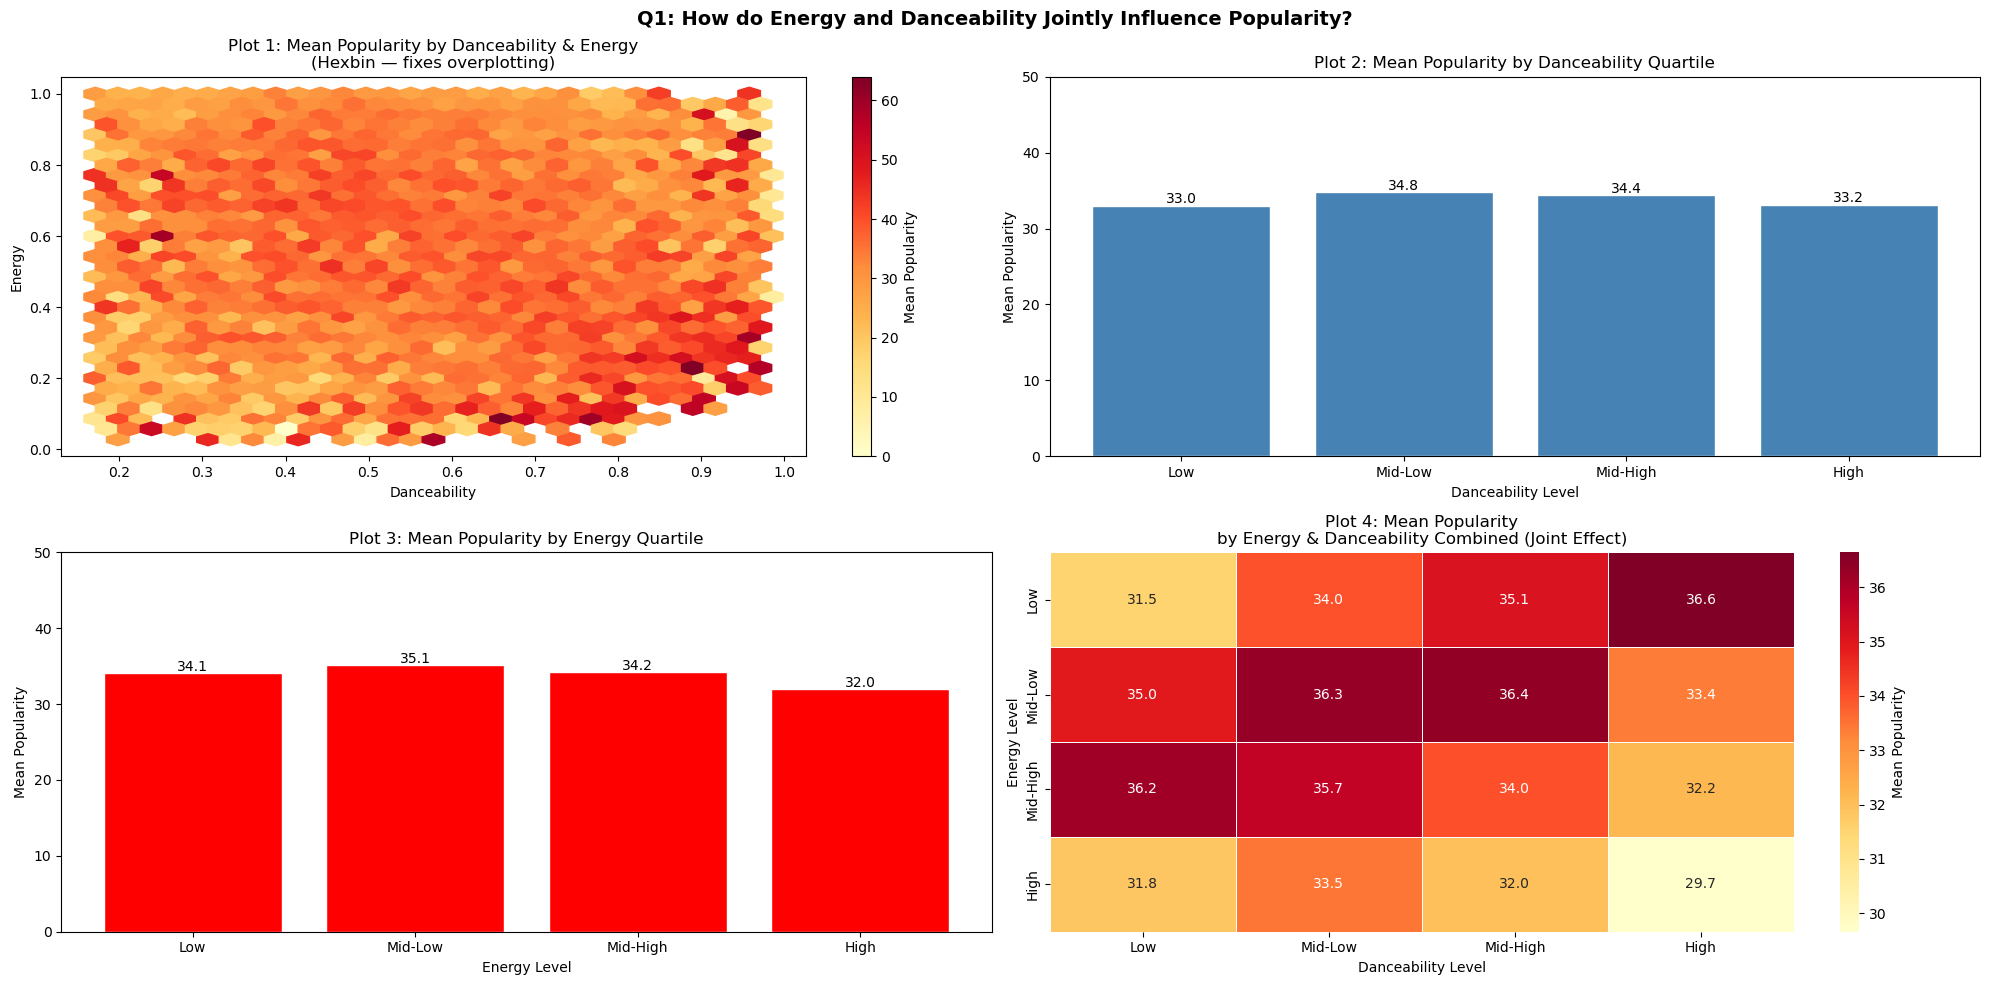

Correlation between danceability and popularity: 0.01
Correlation between energy and popularity: -0.023
Correlation between danceability and energy: -0.019

Mean popularity by danceability quartile:
dance_quartile
Low         33.03
Mid-Low     34.76
Mid-High    34.44
High        33.15
Name: popularity, dtype: float64

Mean popularity by energy quartile:
energy_quartile
Low         34.08
Mid-Low     35.14
Mid-High    34.16
High        32.00
Name: popularity, dtype: float64

Joint effect — mean popularity by energy + danceability combined:
dance_quartile     Low  Mid-Low  Mid-High   High
energy_quartile                                 
Low              31.52    33.99     35.13  36.65
Mid-Low          34.95    36.29     36.37  33.38
Mid-High         36.16    35.66     34.03  32.16
High             31.84    33.48     31.97  29.66


In [39]:
# Q1: How do energy and danceability jointly influence a track's popularity?
# We use 4 plots to fully answer the question

fig = plt.figure(figsize=(20, 10))

# Plot 1: Hexbin — solves overplotting, shows mean popularity density
ax1 = fig.add_subplot(2, 2, 1)
hb  = ax1.hexbin(df['danceability'], df['energy'],
                  C=df['popularity'], gridsize=30,
                  cmap='YlOrRd', reduce_C_function=np.mean)
plt.colorbar(hb, ax=ax1, label='Mean Popularity')
ax1.set_xlabel('Danceability')
ax1.set_ylabel('Energy')
ax1.set_title('Plot 1: Mean Popularity by Danceability & Energy\n(Hexbin — fixes overplotting)')

# Plot 2: Mean popularity by danceability quartile 
ax2 = fig.add_subplot(2, 2, 2)
#qcut create equal bins count
df['dance_quartile'] = pd.qcut(df['danceability'], q=4,
                                labels=['Low', 'Mid-Low', 'Mid-High', 'High'])
dance_pop = df.groupby('dance_quartile')['popularity'].mean()

ax2.bar(dance_pop.index, dance_pop.values, color='steelblue', edgecolor='white')
ax2.set_title('Plot 2: Mean Popularity by Danceability Quartile')
ax2.set_xlabel('Danceability Level')
ax2.set_ylabel('Mean Popularity')
ax2.set_ylim(0, 50)
for i, v in enumerate(dance_pop.values):
    ax2.text(i, v + 0.3, f'{v:.1f}', ha='center', fontsize=10)

# Plot 3: Mean popularity by energy quartile 
ax3 = fig.add_subplot(2, 2, 3)
df['energy_quartile'] = pd.qcut(df['energy'], q=4,
                                 labels=['Low', 'Mid-Low', 'Mid-High', 'High'])
energy_pop = df.groupby('energy_quartile')['popularity'].mean()

ax3.bar(energy_pop.index, energy_pop.values, color='red', edgecolor='white')
ax3.set_title('Plot 3: Mean Popularity by Energy Quartile')
ax3.set_xlabel('Energy Level')
ax3.set_ylabel('Mean Popularity')
ax3.set_ylim(0, 50)
for i, v in enumerate(energy_pop.values):
    ax3.text(i, v + 0.3, f'{v:.1f}', ha='center', fontsize=10)

# Plot 4: JOINT effect — popularity across combined danceability+energy bins
# This directly answers the jointly part of the question
ax4 = fig.add_subplot(2, 2, 4)

# Creating a pivot table: rows = energy quartile, columns = dance quartile
# Values = mean popularity — shows the combined effect clearly
joint_pivot = df.groupby(['energy_quartile', 'dance_quartile'])['popularity'].mean().unstack()

sns.heatmap(joint_pivot, annot=True, fmt='.1f', cmap='YlOrRd',
            linewidths=0.5, ax=ax4,
            cbar_kws={'label': 'Mean Popularity'})
ax4.set_title('Plot 4: Mean Popularity\nby Energy & Danceability Combined (Joint Effect)')
ax4.set_xlabel('Danceability Level')
ax4.set_ylabel('Energy Level')

plt.suptitle('Q1: How do Energy and Danceability Jointly Influence Popularity?',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Supporting statistics
print("Correlation between danceability and popularity:",
      round(df['danceability'].corr(df['popularity']), 3))
print("Correlation between energy and popularity:",
      round(df['energy'].corr(df['popularity']), 3))
print("Correlation between danceability and energy:",
      round(df['danceability'].corr(df['energy']), 3))

print("\nMean popularity by danceability quartile:")
print(dance_pop.round(2))
print("\nMean popularity by energy quartile:")
print(energy_pop.round(2))

print("\nJoint effect — mean popularity by energy + danceability combined:")
print(joint_pivot.round(2))

---
### Q2 — How does loudness relate to a track's popularity, and does this relationship differ between explicit and non-explicit tracks?

**Intent:** This plot explores whether louder tracks are more popular, and whether  
explicit tracks behave differently from non-explicit tracks in this relationship.

**Description:** The left chart shows mean popularity across binned loudness ranges  
for explicit vs non-explicit tracks side by side. The right boxplot compares the  
overall popularity distribution between the two groups.


Explicit trend     : increasing  (slope = 0.2283)
Non-Explicit trend : increasing  (slope = 1.0372)


C:\Users\hazmm\AppData\Local\Temp\ipykernel_43844\3781767674.py:60: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='explicit_label', y='popularity',


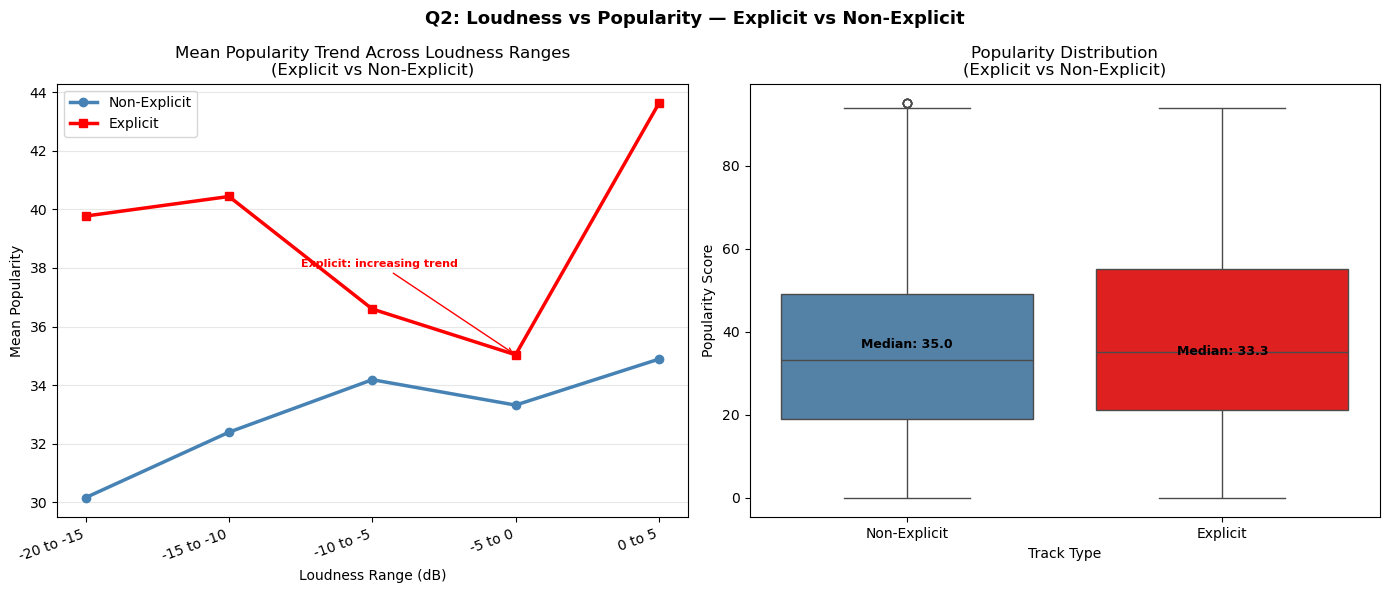

         Supporting Statistics — Q2

Correlation (loudness vs popularity):
  Non-Explicit : 0.02  → very weak relationship
  Explicit     : -0.059  → very weak relationship

Average popularity:
  Non-Explicit : 33.58
  Explicit     : 36.46

Median popularity:
  Non-Explicit : 33.26
  Explicit     : 35.0

T-test (Explicit vs Non-Explicit popularity):
  t-statistic : 12.0968
  p-value     : 0.0000
  Result      : Statistically significant difference (p < 0.05)

Mean popularity per loudness bin — Non-Explicit:
loudness_bin
-20 to -15    30.16
-15 to -10    32.40
-10 to -5     34.19
-5 to 0       33.32
0 to 5        34.89
Name: popularity, dtype: float64

Mean popularity per loudness bin — Explicit:
loudness_bin
-20 to -15    39.77
-15 to -10    40.44
-10 to -5     36.60
-5 to 0       35.04
0 to 5        43.61
Name: popularity, dtype: float64


In [27]:
# Q2: How does loudness relate to popularity for explicit vs non-explicit tracks?

explicit_df     = df[df['explicit'] == 1].copy()
non_explicit_df = df[df['explicit'] == 0].copy()

## Creating explicit label column for plots
df['explicit_label'] = df['explicit'].map({0: 'Non-Explicit', 1: 'Explicit'})

## Binning loudness into ranges for clearer trend comparison
bins   = [-20, -15, -10, -5, 0, 5]
labels = ['-20 to -15', '-15 to -10', '-10 to -5', '-5 to 0', '0 to 5']
#cut for equal width
explicit_df['loudness_bin']     = pd.cut(explicit_df['loudness'],
                                          bins=bins, labels=labels)
non_explicit_df['loudness_bin'] = pd.cut(non_explicit_df['loudness'],
                                          bins=bins, labels=labels)

exp_binned     = explicit_df.groupby('loudness_bin', observed=True)['popularity'].mean()
non_exp_binned = non_explicit_df.groupby('loudness_bin', observed=True)['popularity'].mean()

## Compute actual trend directions from slope BEFORE plotting
m_exp,     _ = np.polyfit(range(len(labels)), exp_binned.values,     1)
m_non_exp, _ = np.polyfit(range(len(labels)), non_exp_binned.values, 1)

exp_direction     = 'increasing' if m_exp     > 0 else 'decreasing'
non_exp_direction = 'increasing' if m_non_exp > 0 else 'decreasing'

print(f'Explicit trend     : {exp_direction}  (slope = {m_exp:.4f})')
print(f'Non-Explicit trend : {non_exp_direction}  (slope = {m_non_exp:.4f})')

## 2 plots only — line chart shows trend, boxplot shows distribution
## Plot 3 (scatter with regression) removed — trend lines added clutter
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

## Plot 1: Line chart — clearly shows trend direction for each group
x_pos = range(len(labels))

axes[0].plot(x_pos, non_exp_binned.values, marker='o',
             color='steelblue', linewidth=2.5, label='Non-Explicit')
axes[0].plot(x_pos, exp_binned.values, marker='s',
             color='red', linewidth=2.5, label='Explicit')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(labels, rotation=20, ha='right')
axes[0].set_title('Mean Popularity Trend Across Loudness Ranges\n(Explicit vs Non-Explicit)',
                  fontsize=12)
axes[0].set_xlabel('Loudness Range (dB)')
axes[0].set_ylabel('Mean Popularity')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

## Annotate actual direction — computed from slope, not assumed
axes[0].annotate(f'Explicit: {exp_direction} trend',
                 xy=(3, exp_binned.values[3]),
                 xytext=(1.5, exp_binned.values[3] + 3),
                 fontsize=8, color='red', fontweight='bold',
                 arrowprops=dict(arrowstyle='->', color='red'))

## Plot 2: Boxplot — shows full popularity distribution per group
sns.boxplot(data=df, x='explicit_label', y='popularity',
            palette={'Explicit': 'red', 'Non-Explicit': 'steelblue'},
            ax=axes[1])
axes[1].set_title('Popularity Distribution\n(Explicit vs Non-Explicit)',
                  fontsize=12)
axes[1].set_xlabel('Track Type')
axes[1].set_ylabel('Popularity Score')

## Add median labels so values are readable without guessing from the chart
for i, label in enumerate(['Explicit', 'Non-Explicit']):
    median = df[df['explicit_label'] == label]['popularity'].median()
    axes[1].text(i, median + 1, f'Median: {median:.1f}',
                 ha='center', fontsize=9, fontweight='bold')

plt.suptitle('Q2: Loudness vs Popularity — Explicit vs Non-Explicit',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Supporting statistics
from scipy import stats

corr_non_exp = round(non_explicit_df['loudness'].corr(non_explicit_df['popularity']), 3)
corr_exp     = round(explicit_df['loudness'].corr(explicit_df['popularity']), 3)

print('=' * 55)
print('         Supporting Statistics — Q2')
print('=' * 55)

print(f'\nCorrelation (loudness vs popularity):')
print(f'  Non-Explicit : {corr_non_exp}  → very weak relationship')
print(f'  Explicit     : {corr_exp}  → very weak relationship')

print(f'\nAverage popularity:')
print(f'  Non-Explicit : {round(non_explicit_df["popularity"].mean(), 2)}')
print(f'  Explicit     : {round(explicit_df["popularity"].mean(), 2)}')

print(f'\nMedian popularity:')
print(f'  Non-Explicit : {round(non_explicit_df["popularity"].median(), 2)}')
print(f'  Explicit     : {round(explicit_df["popularity"].median(), 2)}')

t_stat, p_val = stats.ttest_ind(explicit_df['popularity'],
                                 non_explicit_df['popularity'])
print(f'\nT-test (Explicit vs Non-Explicit popularity):')
print(f'  t-statistic : {t_stat:.4f}')
print(f'  p-value     : {p_val:.4f}')
if p_val < 0.05:
    print('  Result      : Statistically significant difference (p < 0.05)')
else:
    print('  Result      : No statistically significant difference (p >= 0.05)')

print(f'\nMean popularity per loudness bin — Non-Explicit:')
print(non_exp_binned.round(2))
print(f'\nMean popularity per loudness bin — Explicit:')
print(exp_binned.round(2))

---
### Q3 — How does valence (musical positivity) vary across genres, and is there a pattern linking happier-sounding music to higher popularity?

**Intent:** We investigate whether genres with higher valence (more positive/happy music)  
tend to be more popular on Spotify. This helps us understand whether emotional tone  
drives commercial success.

**Description:** The left chart ranks genres by average valence — red for below-median,  
blue for above-median. The right scatter plot shows valence vs popularity per genre  
with only the top 5 most popular genres labelled to reduce clutter.


Correlation computed: r = -0.052  (negligible)


C:\Users\hazmm\AppData\Local\Temp\ipykernel_43844\2383426321.py:26: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined  = pd.concat([bot10, separator, top10], ignore_index=True)


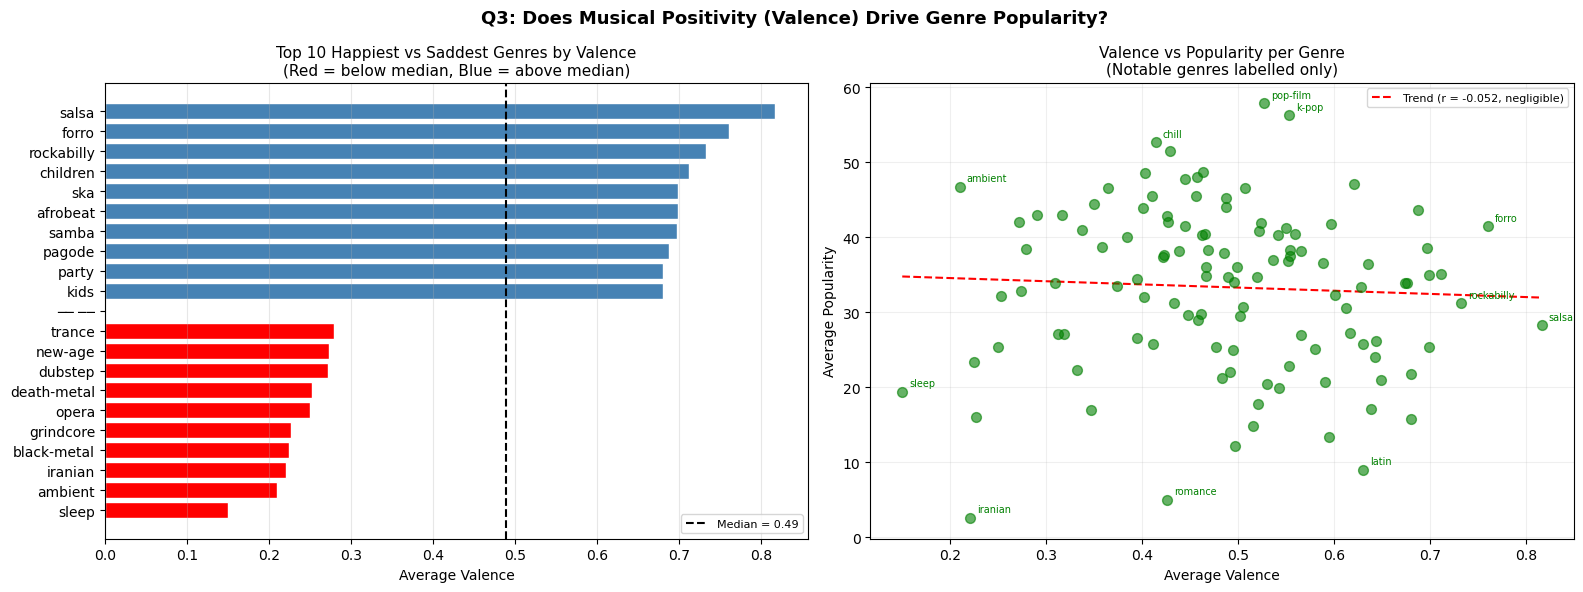

        Supporting Statistics — Q3

Pearson Correlation : -0.052
P-value             : 0.582
Strength            : negligible

Note: The correlation is negligible and not statistically significant.
This means valence alone does NOT reliably predict genre popularity.

Top 5 happiest genres (highest valence):
track_genre  avg_valence  avg_popularity
      salsa     0.816696       28.237054
      forro     0.760438       41.480911
 rockabilly     0.732590       31.216085
   children     0.711997       35.108718
        ska     0.699068       34.950551

Top 5 most popular genres:
track_genre  avg_valence  avg_popularity
   pop-film     0.527090       57.832777
      k-pop     0.553417       56.227899
      chill     0.414156       52.645841
        sad     0.428945       51.517875
     indian     0.463786       48.699133

Average valence — Top 5 popular genres   : 0.477
Average valence — Bottom 5 popular genres: 0.474


In [40]:
# Q3: How does valence vary across genres and relate to popularity?

genre_valence = df.groupby('track_genre').agg(
    {'valence': 'mean', 'popularity': 'mean'}
).reset_index()
genre_valence.columns = ['track_genre', 'avg_valence', 'avg_popularity']

## Compute correlation FIRST — used in both the plot label and stats output
## This prevents hardcoding the wrong r value
corr_val, p_val = stats.pearsonr(genre_valence['avg_valence'],
                                  genre_valence['avg_popularity'])

strength = ('negligible' if abs(corr_val) < 0.1 else
            'weak'       if abs(corr_val) < 0.3 else 'moderate')

print(f'Correlation computed: r = {corr_val:.3f}  ({strength})')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

## Plot 1: Top 10 happiest vs saddest genres — clean horizontal bar chart
top10 = genre_valence.nlargest(10,  'avg_valence').sort_values('avg_valence')
bot10 = genre_valence.nsmallest(10, 'avg_valence').sort_values('avg_valence')

separator = pd.DataFrame([{'track_genre': '── ──',
                            'avg_valence': None, 'avg_popularity': None}])
combined  = pd.concat([bot10, separator, top10], ignore_index=True)

median_val = genre_valence['avg_valence'].median()
colors = []
for v in combined['avg_valence']:
    if v is None:
        colors.append('white')
    elif v < median_val:
        colors.append('red')
    else:
        colors.append('steelblue')

axes[0].barh(combined['track_genre'],
             combined['avg_valence'].fillna(0),
             color=colors, edgecolor='white')
axes[0].axvline(median_val, color='black', linestyle='--',
                linewidth=1.5, label=f'Median = {median_val:.2f}')
axes[0].set_title('Top 10 Happiest vs Saddest Genres by Valence\n'
                  '(Red = below median, Blue = above median)', fontsize=11)
axes[0].set_xlabel('Average Valence')
axes[0].legend(fontsize=8)
axes[0].grid(axis='x', alpha=0.3)

## Plot 2: Scatter — valence vs popularity per genre
## Only notable genres labelled — no clutter
axes[1].scatter(genre_valence['avg_valence'], genre_valence['avg_popularity'],
                color='green', s=50, alpha=0.6, zorder=3)

notable = pd.concat([
    genre_valence.nlargest(3,  'avg_popularity'),
    genre_valence.nsmallest(3, 'avg_popularity'),
    genre_valence.nlargest(3,  'avg_valence'),
    genre_valence.nsmallest(3, 'avg_valence')
]).drop_duplicates()

for _, row in notable.iterrows():
    axes[1].annotate(row['track_genre'],
                     (row['avg_valence'], row['avg_popularity']),
                     fontsize=7, color='green',
                     xytext=(5, 4), textcoords='offset points')

## Trend line — label uses computed r value, not hardcoded
m, b   = np.polyfit(genre_valence['avg_valence'], genre_valence['avg_popularity'], 1)
x_line = np.linspace(genre_valence['avg_valence'].min(),
                     genre_valence['avg_valence'].max(), 100)

axes[1].plot(x_line, m * x_line + b, 'r--', linewidth=1.5,
             label=f'Trend (r = {corr_val:.3f}, {strength})')
axes[1].set_xlabel('Average Valence')
axes[1].set_ylabel('Average Popularity')
axes[1].set_title('Valence vs Popularity per Genre\n(Notable genres labelled only)',
                  fontsize=11)
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.2)

plt.suptitle('Q3: Does Musical Positivity (Valence) Drive Genre Popularity?',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## Supporting statistics
print('=' * 55)
print('        Supporting Statistics — Q3')
print('=' * 55)

print(f'\nPearson Correlation : {corr_val:.3f}')
print(f'P-value             : {p_val:.3f}')
print(f'Strength            : {strength}')

significance = 'statistically significant' if p_val < 0.05 else 'not statistically significant'
print(f'\nNote: The correlation is {strength} and {significance}.')
print('This means valence alone does NOT reliably predict genre popularity.')

print(f'\nTop 5 happiest genres (highest valence):')
print(genre_valence.nlargest(5, 'avg_valence')[
    ['track_genre', 'avg_valence', 'avg_popularity']].to_string(index=False))

print(f'\nTop 5 most popular genres:')
print(genre_valence.nlargest(5, 'avg_popularity')[
    ['track_genre', 'avg_valence', 'avg_popularity']].to_string(index=False))

print(f'\nAverage valence — Top 5 popular genres   :',
      round(genre_valence.nlargest(5,  'avg_popularity')['avg_valence'].mean(), 3))
print(f'Average valence — Bottom 5 popular genres:',
      round(genre_valence.nsmallest(5, 'avg_popularity')['avg_valence'].mean(), 3))

## Q4 Analysis — Tempo, Danceability, and Popularity

The supporting statistics show **weak correlations** between tempo and both danceability and popularity at the genre level. This means a genre's average tempo does not reliably predict how danceable or popular it tends to be.

The second chart compares the popularity of the highest- and lowest-tempo genres directly. There is no consistent pattern where either extreme clusters at higher popularity — which confirms the weak correlation.

**What the data does support:** There is notable scatter in the tempo–danceability plot with no clear directional trend. Genre labels on each bubble allow individual genres to be identified, so observations can be tied back to specific data points rather than inferred from bubble size alone.

> **Limitation:** Because many genres overlap in tempo range and bubble sizes are close together, conclusions about popularity should rely on the printed correlation values rather than visual inspection of bubble size.


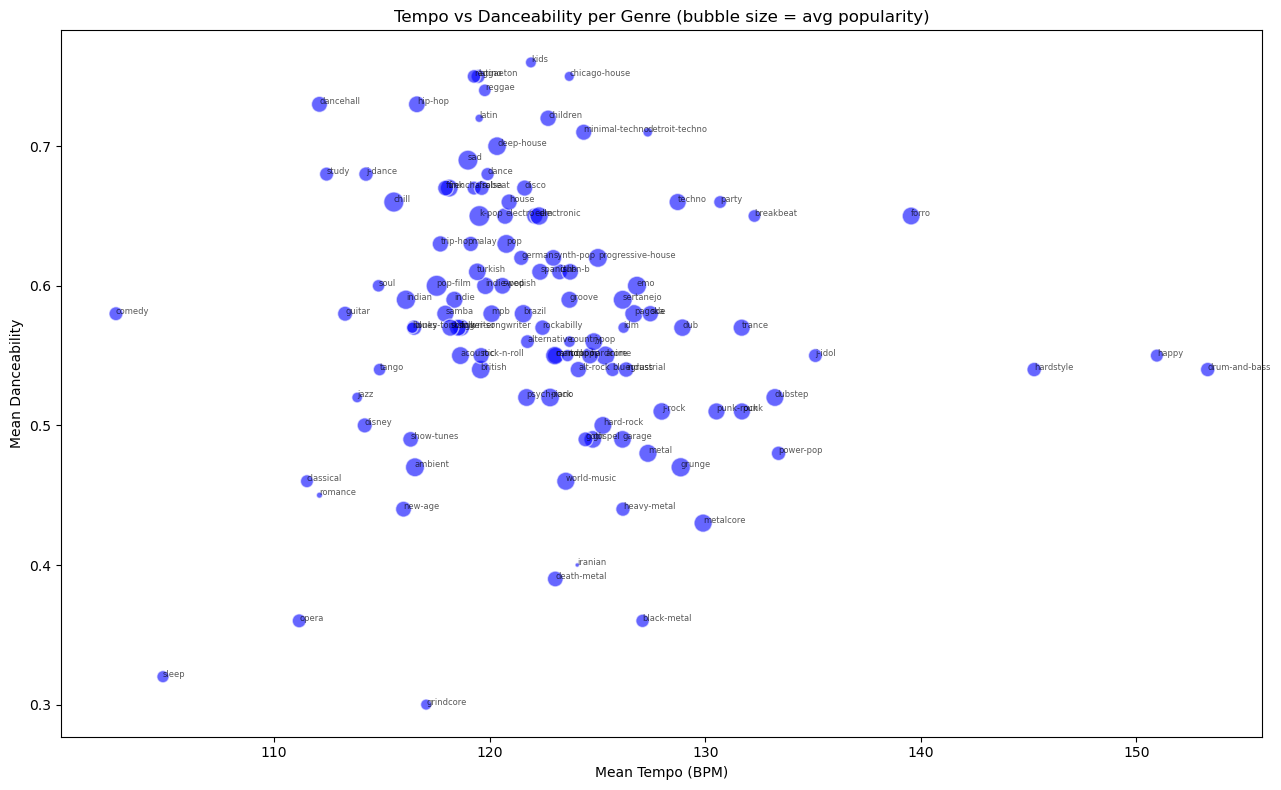

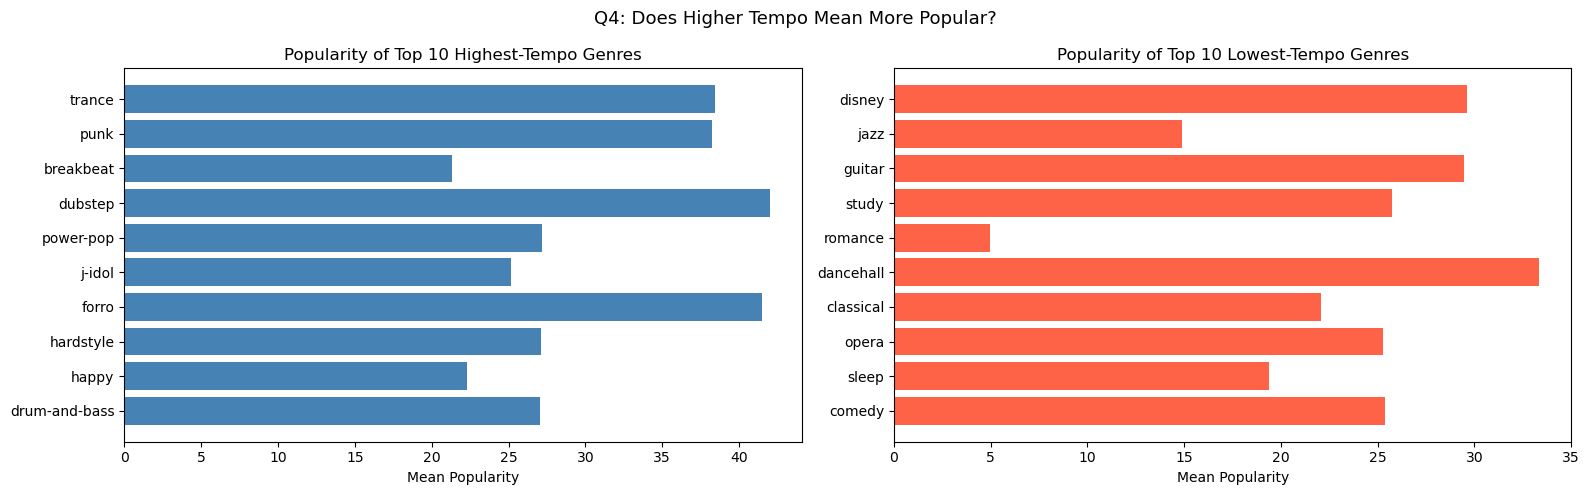

Correlation between avg_tempo and avg_danceability: -0.046
Correlation between avg_tempo and avg_popularity:   0.073


In [29]:
# Q4: How does tempo vary across genres, and does higher tempo correlate with danceability and popularity?

# Plot 1: Scatter — Tempo vs Danceability, bubble size = avg popularity, with genre labels
plt.figure(figsize=(13, 8))
plt.scatter(genre_stats['avg_tempo'], genre_stats['avg_danceability'],
            s=genre_stats['avg_popularity'] * 4,
            alpha=0.6, color='blue', edgecolors='white')

# Adding genre labels so each point can be identified
for _, row in genre_stats.iterrows():
    plt.annotate(row['track_genre'],
                 (row['avg_tempo'], row['avg_danceability']),
                 fontsize=6, alpha=0.65)

plt.xlabel('Mean Tempo (BPM)')
plt.ylabel('Mean Danceability')
plt.title('Tempo vs Danceability per Genre (bubble size = avg popularity)')
plt.tight_layout()
plt.show()

# Plot 2: Popularity of highest-tempo vs lowest-tempo genres
top10_tempo = genre_stats.nlargest(10, 'avg_tempo')[['track_genre', 'avg_tempo', 'avg_popularity']]
bot10_tempo = genre_stats.nsmallest(10, 'avg_tempo')[['track_genre', 'avg_tempo', 'avg_popularity']]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].barh(top10_tempo['track_genre'], top10_tempo['avg_popularity'], color='steelblue')
axes[0].set_xlabel('Mean Popularity')
axes[0].set_title('Popularity of Top 10 Highest-Tempo Genres')

axes[1].barh(bot10_tempo['track_genre'], bot10_tempo['avg_popularity'], color='tomato')
axes[1].set_xlabel('Mean Popularity')
axes[1].set_title('Popularity of Top 10 Lowest-Tempo Genres')

plt.suptitle('Q4: Does Higher Tempo Mean More Popular?', fontsize=13)
plt.tight_layout()
plt.show()

# Supporting statistics
corr_tempo_dance = round(genre_stats['avg_tempo'].corr(genre_stats['avg_danceability']), 3)
corr_tempo_pop   = round(genre_stats['avg_tempo'].corr(genre_stats['avg_popularity']),   3)
print("Correlation between avg_tempo and avg_danceability:", corr_tempo_dance)
print("Correlation between avg_tempo and avg_popularity:  ", corr_tempo_pop)


## Q5 Analysis — Track Duration and Popularity

The scatter plot shows a very weak and essentially flat relationship between track duration and popularity. The correlation value confirms this — it is close to zero, meaning duration is not a meaningful predictor of how popular a track will be.

Most popular tracks appear in the typical song-length range (roughly 2–5 minutes), but this reflects the distribution of the dataset rather than a causal link between length and popularity.

**What the data does not support:** We cannot conclude that shorter or longer tracks are systematically more popular. The correlation is too weak to draw any directional conclusion, and the scatter plot shows no visible trend in either direction.


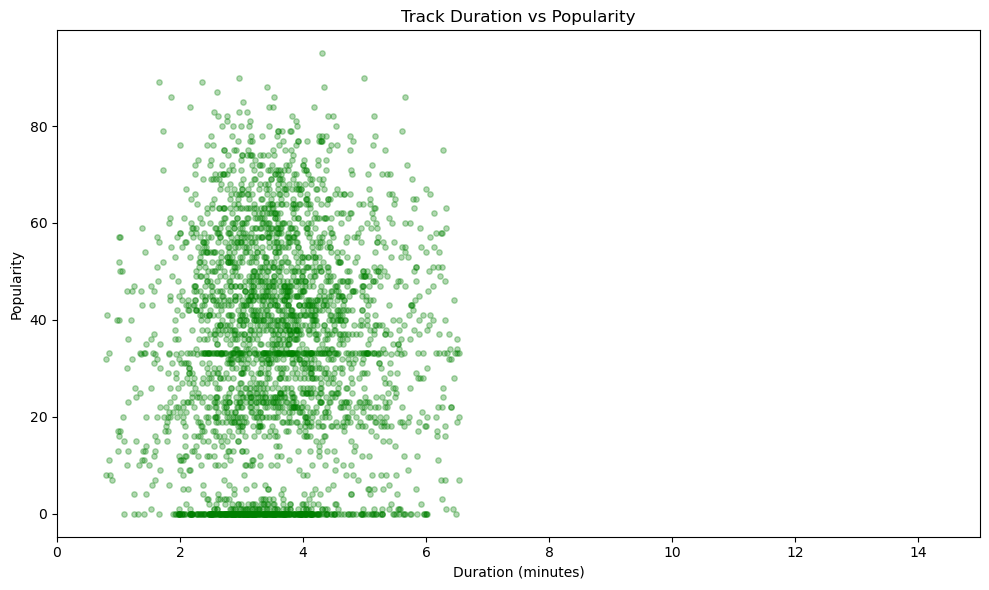

Correlation between duration_min and popularity: 0.043


In [30]:
# Q5: How does track duration relate to popularity?

# Converting duration from seconds to minutes for readability
df['duration_min'] = df['duration_sec'] / 60

# Scatter: Duration vs Popularity (sampled for readability)
sample2 = df.sample(3000, random_state=1)
plt.figure(figsize=(10, 6))
plt.scatter(sample2['duration_min'], sample2['popularity'],
            alpha=0.3, s=15, color='green')
plt.xlabel('Duration (minutes)')
plt.ylabel('Popularity')
plt.title('Track Duration vs Popularity')
plt.xlim(0, 15)
plt.tight_layout()
plt.show()

# Supporting statistics
corr_dur_pop = round(df['duration_min'].corr(df['popularity']), 3)
print("Correlation between duration_min and popularity:", corr_dur_pop)


## Q6 Analysis — Acousticness vs Energy Across Genres

The scatter plot reveals a clear **negative relationship** between acousticness and energy at the genre level: genres with higher average acousticness consistently show lower energy levels, while high-energy genres show very low acousticness.

The correlation value supports this — it is strongly negative, meaning the trade-off between acoustic and energetic character is consistent across genres.

**Interpretation:** This pattern makes intuitive sense given what these features measure. Acoustic instruments produce a quieter, more organic sound profile that naturally sits at lower energy levels, while genres built around electronic amplification or synthesized production (EDM, metal, dance) tend to maximize energy and minimize acoustic character. The genre labels on each point allow this distinction to be observed directly in the data.


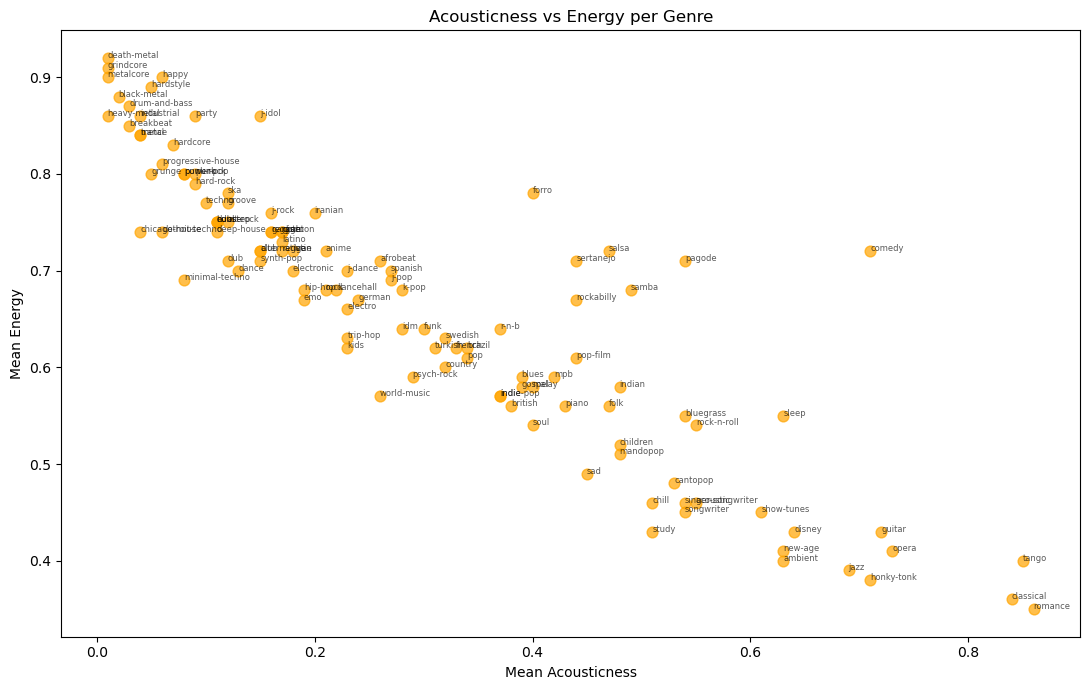

Correlation between avg_acousticness and avg_energy: -0.891


In [31]:
# Q6: How does the relationship between acousticness and energy differ across genres?

plt.figure(figsize=(11, 7))
plt.scatter(genre_stats['avg_acousticness'], genre_stats['avg_energy'],
            color='orange', alpha=0.7, s=60)

# Labeling each genre so individual points can be traced back
for _, row in genre_stats.iterrows():
    plt.annotate(row['track_genre'],
                 (row['avg_acousticness'], row['avg_energy']),
                 fontsize=6, alpha=0.65)

plt.xlabel('Mean Acousticness')
plt.ylabel('Mean Energy')
plt.title('Acousticness vs Energy per Genre')
plt.tight_layout()
plt.show()

# Supporting statistics
corr_ac_en = round(genre_stats['avg_acousticness'].corr(genre_stats['avg_energy']), 3)
print("Correlation between avg_acousticness and avg_energy:", corr_ac_en)


---
### Q7 — How does the distribution of danceability, energy, and valence differ between the top 5 and bottom 5 popular genres?

**Intent:** We compare the audio profile of the most popular genres against the least popular  
to identify which features separate them.

**Description:** Three side-by-side boxplots compare danceability, energy, and valence  
for the top 5 most popular genres vs the bottom 5.


Top 5: ['pop-film', 'k-pop', 'chill', 'sad', 'indian']
Bottom 5: ['iranian', 'romance', 'latin', 'detroit-techno', 'chicago-house']


C:\Users\hazmm\AppData\Local\Temp\ipykernel_43844\3409749216.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='group', y='danceability', data=df_compare,
C:\Users\hazmm\AppData\Local\Temp\ipykernel_43844\3409749216.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='group', y='energy', data=df_compare,
C:\Users\hazmm\AppData\Local\Temp\ipykernel_43844\3409749216.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='group', y='valence', data=df_compare,


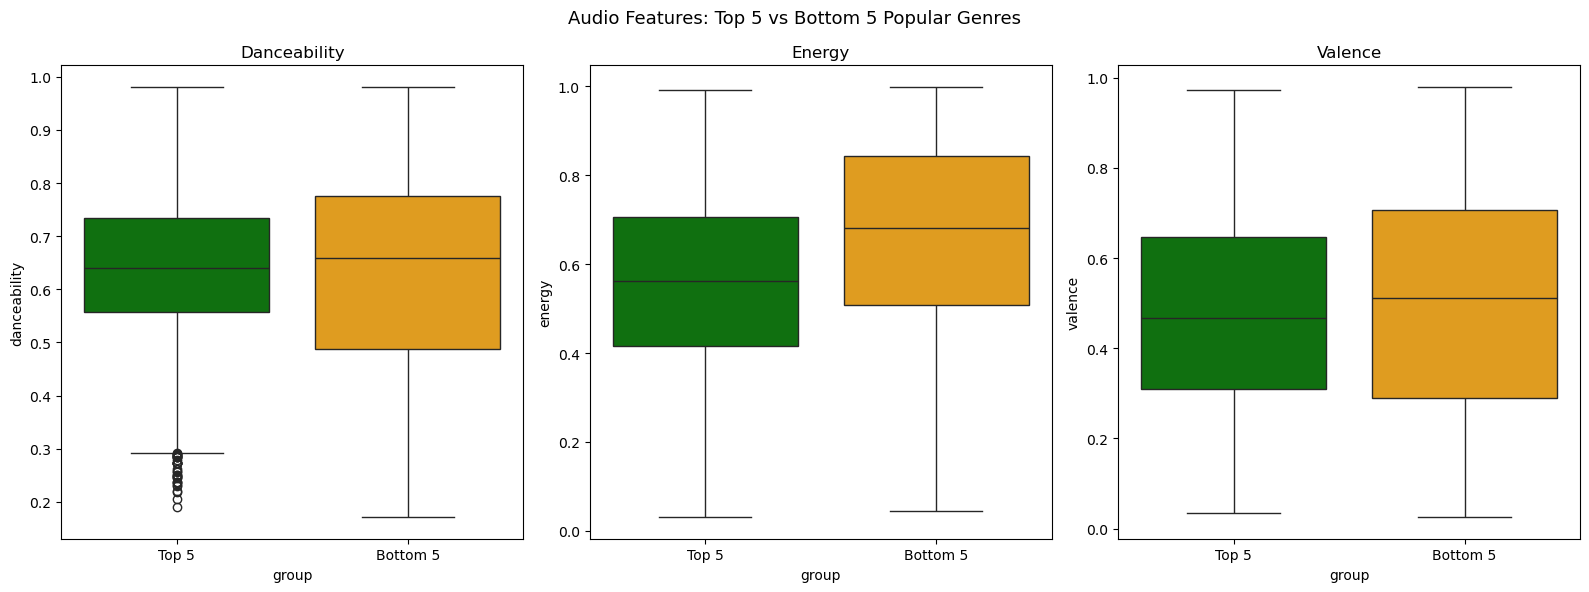

In [32]:
#q7
# Find top and bottom 5 genres by mean popularity
pop_by_genre = df.groupby('track_genre')['popularity'].mean()
top5 = pop_by_genre.nlargest(5).index.tolist()
bot5 = pop_by_genre.nsmallest(5).index.tolist()
print('Top 5:', top5)
print('Bottom 5:', bot5)
df_top = df[df['track_genre'].isin(top5)].copy()
df_top['group'] = 'Top 5'
df_bot = df[df['track_genre'].isin(bot5)].copy()
df_bot['group'] = 'Bottom 5'
df_compare = pd.concat([df_top, df_bot])
fig, axes = plt.subplots(1, 3, figsize=(16, 6))

sns.boxplot(x='group', y='danceability', data=df_compare,
            palette={'Top 5': 'green', 'Bottom 5': 'orange'}, ax=axes[0])
axes[0].set_title('Danceability')

sns.boxplot(x='group', y='energy', data=df_compare,
            palette={'Top 5': 'green', 'Bottom 5': 'orange'}, ax=axes[1])
axes[1].set_title('Energy')

sns.boxplot(x='group', y='valence', data=df_compare,
            palette={'Top 5': 'green', 'Bottom 5': 'orange'}, ax=axes[2])
axes[2].set_title('Valence')

plt.suptitle('Audio Features: Top 5 vs Bottom 5 Popular Genres', fontsize=13)
plt.tight_layout()
plt.show()


---
### Q8 — How does speechiness vary across genres, and what does this reveal about rap vs. instrumental genres?

**Intent:** Speechiness measures how much spoken word is present in a track.  
This chart reveals which genres are speech-heavy and which are purely instrumental.

**Description:** A horizontal bar chart shows the top 20 genres ranked by mean speechiness.

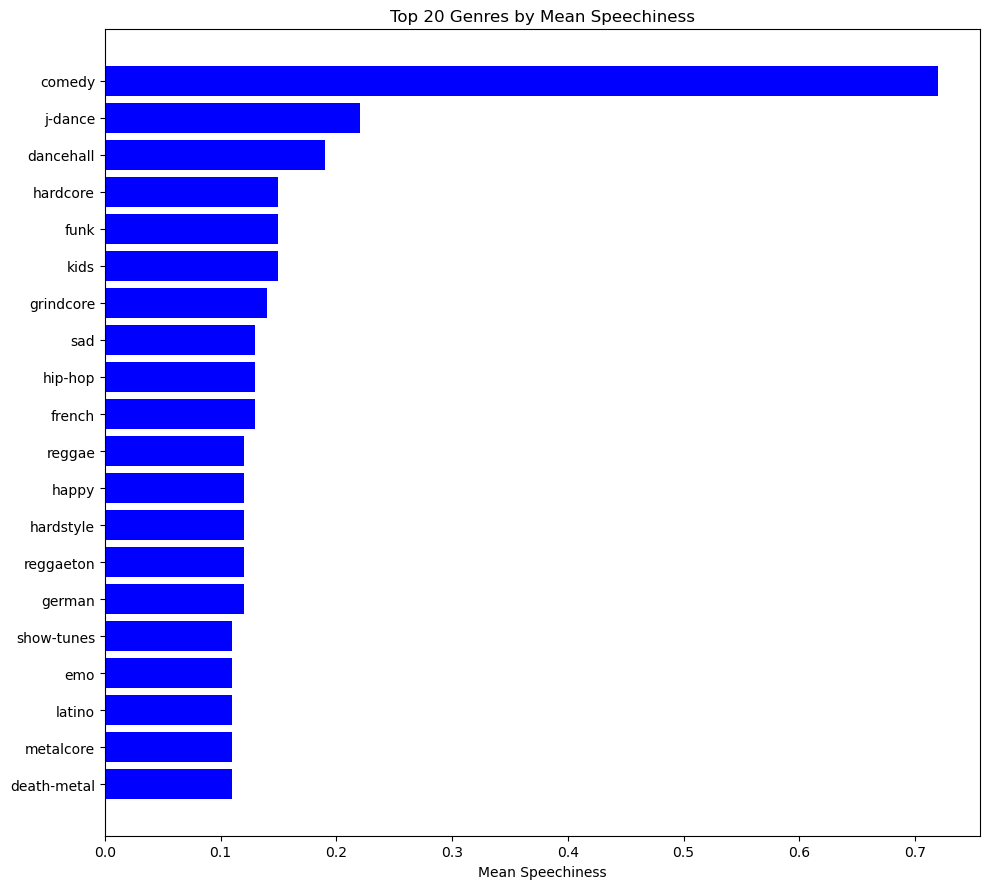

In [33]:
# Q8: How does speechiness vary across genres?

top20_speech = genre_stats.nlargest(20, 'avg_speechiness').sort_values('avg_speechiness')

plt.figure(figsize=(10, 9))
plt.barh(top20_speech['track_genre'], top20_speech['avg_speechiness'], color='blue')
plt.xlabel('Mean Speechiness')
plt.title('Top 20 Genres by Mean Speechiness')
plt.tight_layout()
plt.show()


---
### Q9 — Which combination of audio features is most strongly associated with high popularity scores?

**Intent:** A correlation heatmap shows which audio features have the strongest  
linear relationship with popularity.

**Description:** The heatmap shows the Pearson correlation matrix for all numerical  
audio features and popularity. Warm colours = positive correlation, cool colours = negative.



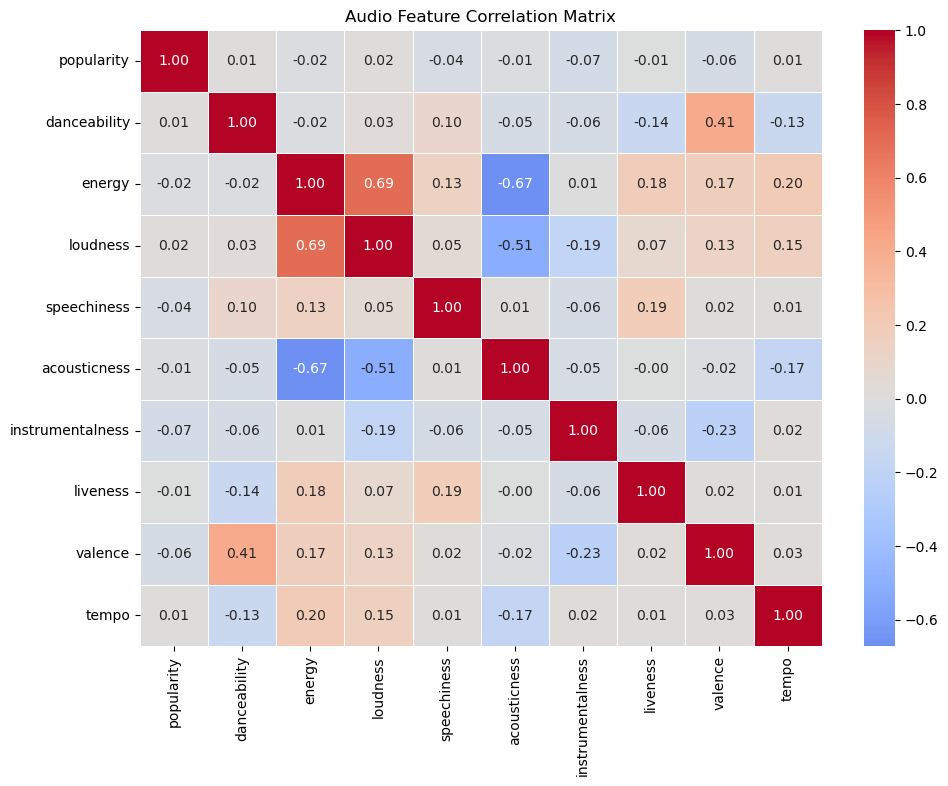

In [34]:
#q9
corr_cols = ['popularity', 'danceability', 'energy', 'loudness',
             'speechiness', 'acousticness', 'instrumentalness',
             'liveness', 'valence', 'tempo']

corr = df[corr_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Audio Feature Correlation Matrix')
plt.show()


---
### Q10 — How does the proportion of explicit tracks vary across genres, and does explicit content correlate with higher popularity?

**Intent:** We examine which genres produce the most explicit tracks and whether  
those tracks score higher in popularity.

**Description:** The left chart shows the explicit rate per genre. The right boxplot  
compares popularity between explicit and non-explicit tracks.


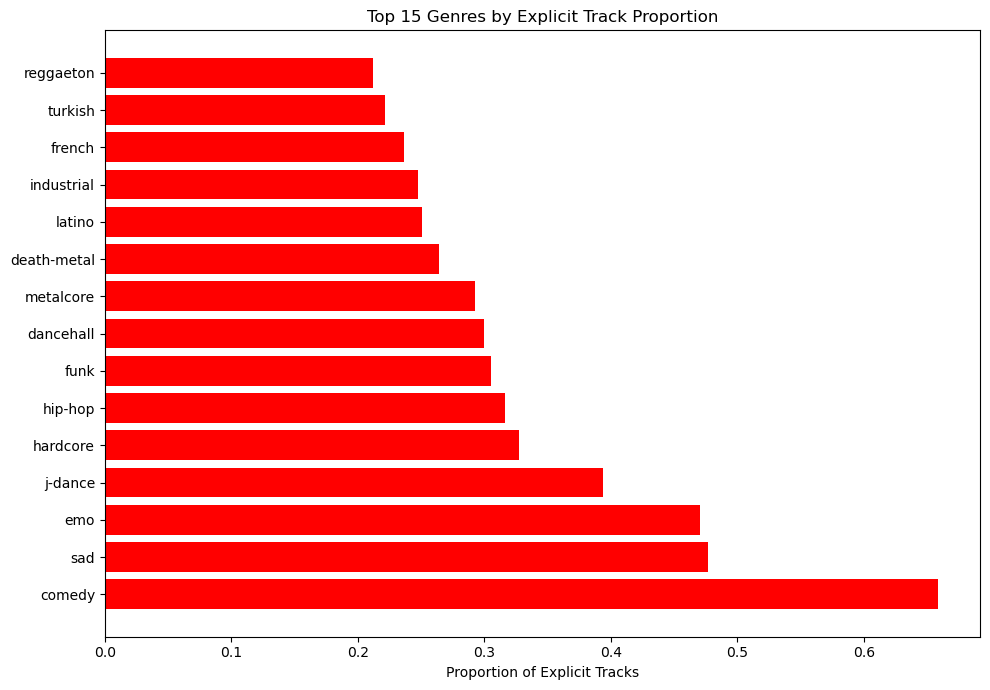

C:\Users\hazmm\AppData\Local\Temp\ipykernel_43844\4055937734.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='explicit_label', y='popularity', data=df,


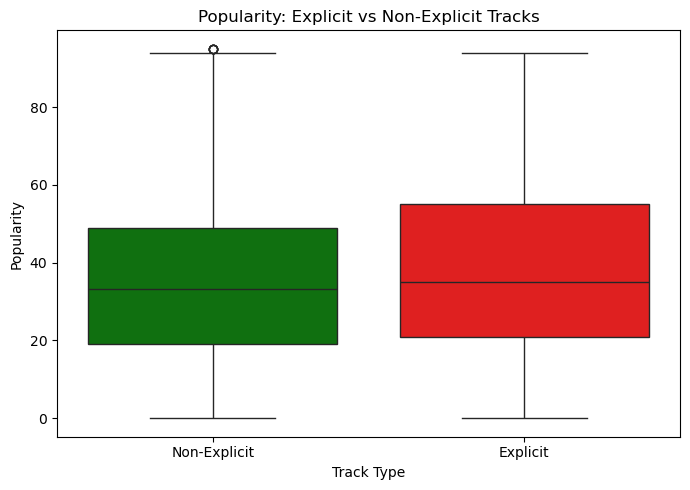

Average popularity by explicit content:
explicit_label
Explicit        36.46
Non-Explicit    33.58
Name: popularity, dtype: float64


In [35]:
# Q10: How does explicit content vary across genres and relate to popularity?

explicit_rate = df.groupby('track_genre')['explicit'].mean().reset_index()
explicit_rate.columns = ['track_genre', 'explicit_rate']
explicit_rate = explicit_rate.sort_values('explicit_rate', ascending=False).head(15)

plt.figure(figsize=(10, 7))
plt.barh(explicit_rate['track_genre'], explicit_rate['explicit_rate'], color='red')
plt.xlabel('Proportion of Explicit Tracks')
plt.title('Top 15 Genres by Explicit Track Proportion')
plt.tight_layout()
plt.show()

# Creating explicit_label column for the boxplot
df['explicit_label'] = df['explicit'].map({0: 'Non-Explicit', 1: 'Explicit'})

plt.figure(figsize=(7, 5))
sns.boxplot(x='explicit_label', y='popularity', data=df,
            palette={'Explicit': 'red', 'Non-Explicit': 'green'})
plt.title('Popularity: Explicit vs Non-Explicit Tracks')
plt.xlabel('Track Type')
plt.ylabel('Popularity')
plt.tight_layout()
plt.show()




# Supporting statistics
print("Average popularity by explicit content:")
print(df.groupby('explicit_label')['popularity'].mean().round(2))


---
### Q11 — How do the audio profiles of the top 20 most popular artists differ from lesser-known artists?

**Intent:** We compare mean energy, danceability, and valence of the top 20 artists  
by popularity against the bottom 20 to find what distinguishes them sonically.

**Description:** A grouped bar chart shows mean energy, danceability, and valence  
for the top 20 vs bottom 20 artists by mean popularity.


              Top 20 Artists  Bottom 20 Artists
energy              0.653463           0.588820
danceability        0.658737           0.597460
valence             0.421728           0.424983


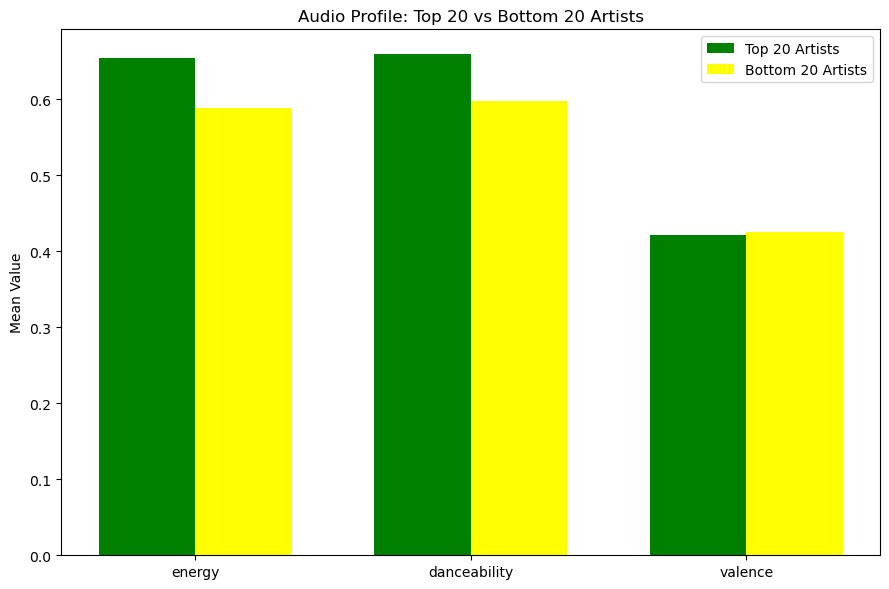

In [36]:
# Q11: How do the audio profiles of top 20 artists differ from lesser-known artists?

# Computing mean audio features per artist
artist_stats = df.groupby('artists')[['popularity', 'energy', 'danceability', 'valence']].mean()
artist_stats = artist_stats.reset_index()

top20_artists = artist_stats.nlargest(20, 'popularity')
bot20_artists = artist_stats.nsmallest(20, 'popularity')

top_means = top20_artists[['energy', 'danceability', 'valence']].mean()
bot_means = bot20_artists[['energy', 'danceability', 'valence']].mean()

compare = pd.DataFrame({'Top 20 Artists': top_means, 'Bottom 20 Artists': bot_means})
print(compare)

x = np.arange(3)
width = 0.35
features = ['energy', 'danceability', 'valence']

plt.figure(figsize=(9, 6))
plt.bar(x - width/2, top_means.values, width, label='Top 20 Artists', color='green')
plt.bar(x + width/2, bot_means.values, width, label='Bottom 20 Artists', color='yellow')
plt.xticks(x, features)
plt.ylabel('Mean Value')
plt.title('Audio Profile: Top 20 vs Bottom 20 Artists')
plt.legend()
plt.tight_layout()
plt.show()


---
### Q12 — How does instrumentalness relate to popularity across genres, and which genres reward more vocal-heavy tracks?

**Intent:** Instrumentalness close to 0 means vocal-heavy; close to 1 means fully instrumental.  
We check if more vocal genres are more popular.

**Description:** The scatter plot shows mean instrumentalness vs mean popularity per genre.  
The bar chart shows the top 15 most instrumental genres.

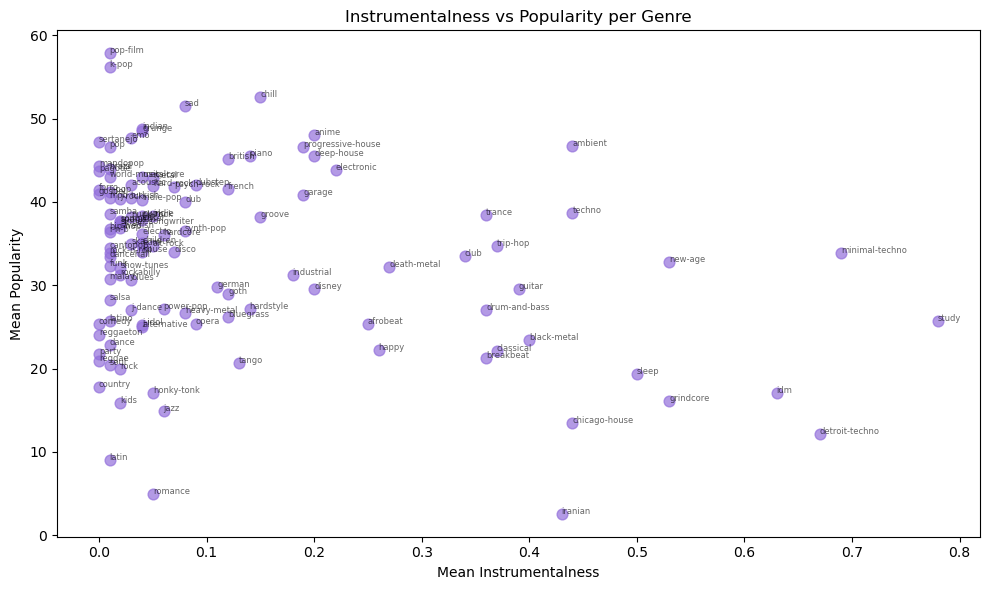

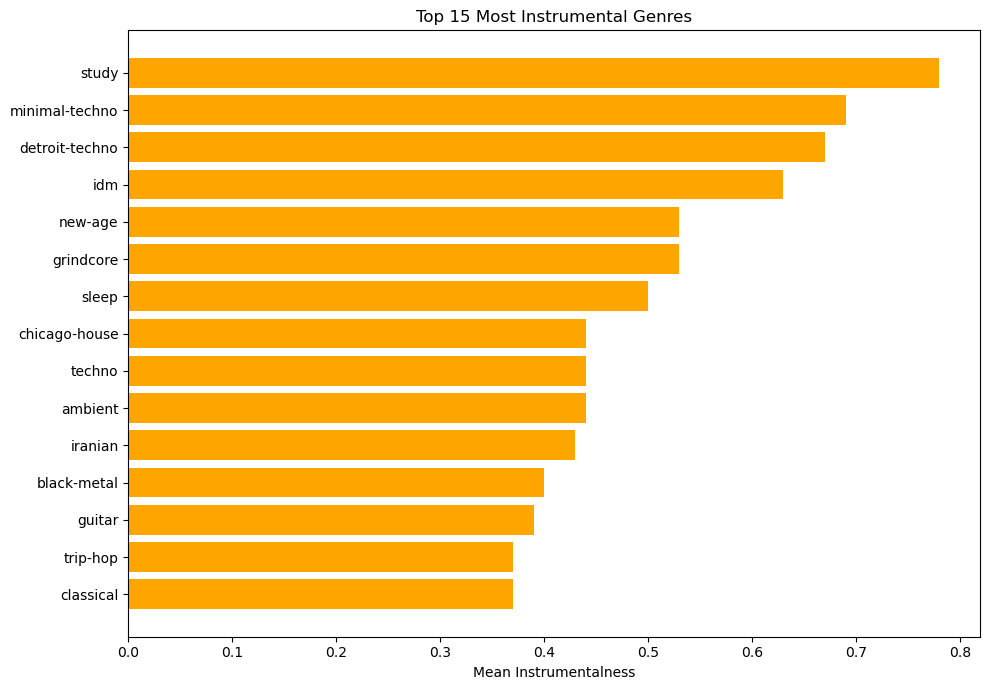

Correlation between avg_instrumentalness and avg_popularity: -0.292


In [37]:
# Q12: How does instrumentalness relate to popularity across genres?

# Scatter plot: instrumentalness vs popularity per genre
plt.figure(figsize=(10, 6))
plt.scatter(genre_stats['avg_instrumentalness'], genre_stats['avg_popularity'],
            color='mediumpurple', alpha=0.7, s=60)

for i, row in genre_stats.iterrows():
    plt.annotate(row['track_genre'],
                 (row['avg_instrumentalness'], row['avg_popularity']),
                 fontsize=6, alpha=0.6)

plt.xlabel('Mean Instrumentalness')
plt.ylabel('Mean Popularity')
plt.title('Instrumentalness vs Popularity per Genre')
plt.tight_layout()
plt.show()

# Bar chart: top 15 most instrumental genres
top15_inst = genre_stats.nlargest(15, 'avg_instrumentalness').sort_values('avg_instrumentalness')

plt.figure(figsize=(10, 7))
plt.barh(top15_inst['track_genre'], top15_inst['avg_instrumentalness'], color='orange')
plt.xlabel('Mean Instrumentalness')
plt.title('Top 15 Most Instrumental Genres')
plt.tight_layout()
plt.show()




# Supporting statistics
print("Correlation between avg_instrumentalness and avg_popularity:",
      round(genre_stats['avg_instrumentalness'].corr(genre_stats['avg_popularity']), 3))
